# Solar Panel Installation Analysis

## Phase 1 — Data Understanding

### 1.1 Data Collection

The purpose of this phase is to understand the structure, characteristics, and quality of the solar installation dataset.

The project focuses on a classification task with customer_segment as the target variable.

The main objective is to identify the characteristics that distinguish residential (RES) from non-residential (NON-RES) solar installations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from matplotlib.patches import FancyBboxPatch

#### Data Loading

According to the dataset documentation, missing values are encoded as -9999.

During data loading, these values are converted to NaN to ensure accurate statistical analysis and proper identification of missing data.

The original dataset remains unchanged.

In [2]:
df = pd.read_csv(
    "LBNL_file.csv",
    na_values=[-9999, "-9999"],
    low_memory=False
)

df.head()

,data_provider_1,data_provider_2,system_ID_1,system_ID_2,installation_date,system_size_DC,total_installed_price,rebate_or_grant,customer_segment,expansion_system,...,built_in_meter_inverter_1,built_in_meter_inverter_2,built_in_meter_inverter_3,output_capacity_inverter_1,output_capacity_inverter_2,output_capacity_inverter_3,DC_optimizer,inverter_loading_ratio,battery_rated_capacity_kW,battery_rated_capacity_kWh
0,Arkansas State Energy Office,NaN,NaN,NaN,29-Apr-2010 00:00:00,2.016,14558.0,0.0,RES,0,...,0.0,NaN,NaN,0.19,NaN,NaN,0.0,1.178947,NaN,NaN
1,Arkansas State Energy Office,NaN,NaN,NaN,26-Apr-2010 00:00:00,3.360,26096.0,0.0,RES,0,...,0.0,NaN,NaN,0.19,NaN,NaN,0.0,1.178947,NaN,NaN
2,Arkansas State Energy Office,NaN,NaN,NaN,20-Apr-2010 00:00:00,13.440,91139.0,0.0,RES,0,...,0.0,NaN,NaN,0.19,NaN,NaN,0.0,1.178947,NaN,NaN
3,Arkansas State Energy Office,NaN,NaN,NaN,21-Apr-2010 00:00:00,5.520,40043.0,0.0,RES,0,...,0.0,NaN,NaN,0.19,NaN,NaN,0.0,1.210526,NaN,NaN
4,Arkansas State Energy Office,NaN,NaN,NaN,22-Apr-2010 00:00:00,2.530,21497.0,0.0,RES,0,...,0.0,NaN,NaN,0.19,NaN,NaN,0.0,1.210526,NaN,NaN


In [3]:
print(f"Number of observations: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

Number of observations: 1,000,000
Number of columns: 78


In [4]:
df["customer_segment"].value_counts(dropna=False)

customer_segment
RES           974311
COM            19693
GOV             3130
NON-PROFIT      1546
SCHOOL          1254
NON-RES           66
Name: count, dtype: int64

## 1.2 Data Description

This section provides an overview of the dataset, including its structure, data types, variables and basic descriptive statistics.

The purpose is to understand the available data and identify potentially relevant features for customer segment classification.

### 1.2.1 Dataset Structure and Variable Overview

This section examines the dataset structure, data types, completeness, and variable cardinality.

In [5]:
# Create and display the complete dataset overview
data_description = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Non-Null Count": df.count(),
    "Unique Values": df.nunique()
})

data_description.index.name = "Variable"

with pd.option_context("display.max_rows", None):
    display(data_description)

,Data Type,Non-Null Count,Unique Values
Variable,,,
data_provider_1,object,1000000,3
data_provider_2,object,221982,2
system_ID_1,object,999895,999895
system_ID_2,object,222098,218662
installation_date,object,1000000,6516
system_size_DC,float64,988692,36030
total_installed_price,float64,814364,172972
rebate_or_grant,float64,954632,25926
customer_segment,object,1000000,6


In [6]:
# Count columns by data type
df.dtypes.value_counts()

float64    51
object     25
int64       2
Name: count, dtype: int64

#### Key Findings

- The dataset contains 1,000,000 observations and 78 variables.
- There are 53 numerical and 25 object-type variables.
- Several variables contain substantial missingness.

### 1.2.2 Variable Categorization

The dataset variables are grouped into semantic categories based on their meaning and purpose.

This categorization supports structured exploratory data analysis, feature engineering, and feature selection for customer segment classification.

In [7]:
variable_categories = {
    "Target Variable": [
        "customer_segment"
    ],

    "Data Sources and System Identifiers": [
        "data_provider_1",
        "data_provider_2",
        "system_ID_1",
        "system_ID_2"
    ],

    "Installation Date": [
        "installation_date"
    ],

    "Geographic Information": [
        "zip_code",
        "city",
        "state",
        "utility_service_territory"
    ],

    "Financial and Ownership Information": [
        "total_installed_price",
        "rebate_or_grant",
        "third_party_owned"
    ],

    "System Configuration": [
        "system_size_DC",
        "expansion_system",
        "multiple_phase_system",
        "new_construction",
        "tracking",
        "ground_mounted"
    ],

    "Installer Information": [
        "installer_name",
        "self_installed"
    ],

    "PV Array Orientation": [
        col for col in df.columns
        if col.startswith(("azimuth_", "tilt_"))
    ],

    "PV Module Characteristics": [
        col for col in df.columns
        if "module" in col.lower()
    ],

    "Inverter and DC Optimizer Characteristics": [
        col for col in df.columns
        if "inverter" in col.lower()
        or col == "DC_optimizer"
    ],

    "Battery Storage Characteristics": [
        "battery_rated_capacity_kW",
        "battery_rated_capacity_kWh"
    ]
}

In [8]:
# Collect all categorized variables
categorized_variables = [
    variable
    for variables in variable_categories.values()
    for variable in variables
]

# Validate category coverage
print("Total dataset variables:", len(df.columns))
print("Categorized variables:", len(categorized_variables))

print("Uncategorized variables:",
      set(df.columns) - set(categorized_variables))

print("Unknown variables:",
      set(categorized_variables) - set(df.columns))

print("Duplicate assignments:",
      len(categorized_variables) - len(set(categorized_variables)))

Total dataset variables: 78
Categorized variables: 78
Uncategorized variables: set()
Unknown variables: set()
Duplicate assignments: 0


In [9]:
category_summary = pd.DataFrame({
    "Category": variable_categories.keys(),
    "Number of Variables": [
        len(variables)
        for variables in variable_categories.values()
    ]
})

category_summary

,Category,Number of Variables
0,Target Variable,1
1,Data Sources and System Identifiers,4
2,Installation Date,1
3,Geographic Information,4
4,Financial and Ownership Information,3
5,System Configuration,6
6,Installer Information,2
7,PV Array Orientation,6
8,PV Module Characteristics,25
9,Inverter and DC Optimizer Characteristics,24


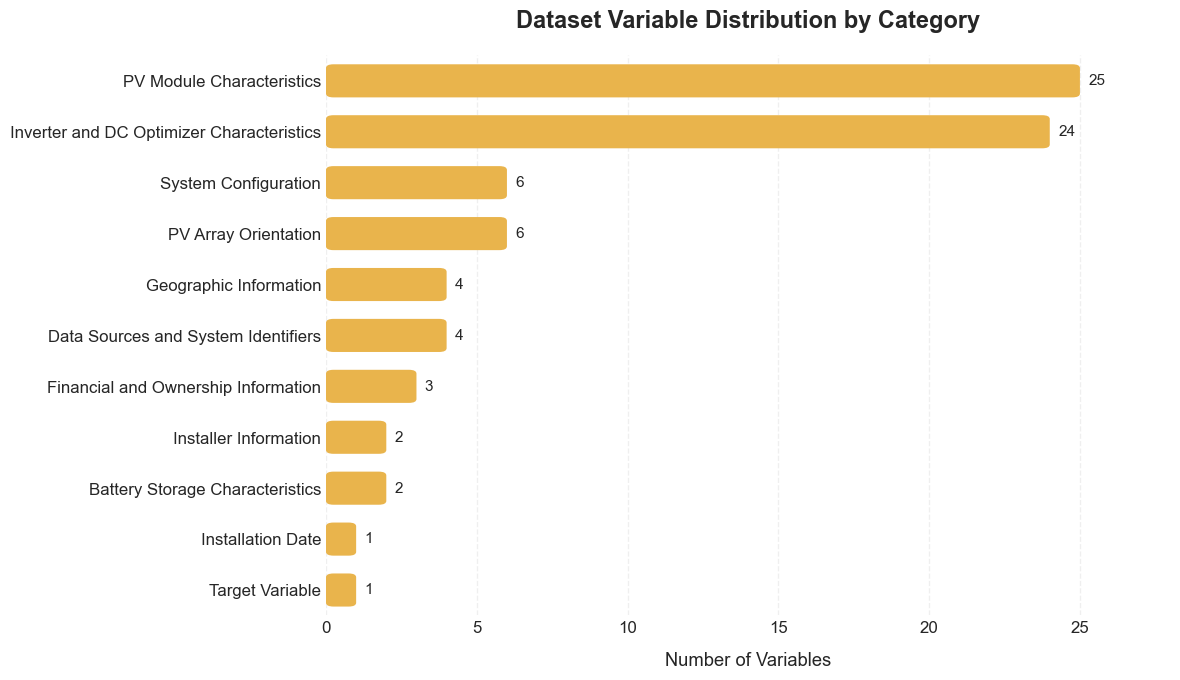

In [10]:
# Set visualization style
sns.set_theme(style="whitegrid", font_scale=1.1)

fig, ax = plt.subplots(figsize=(12, 7))

sns.barplot(
    data=category_summary.sort_values(
        "Number of Variables", ascending=False
    ),
    x="Number of Variables",
    y="Category",
    color="#E9B44C",
    saturation=1,
    width=0.65,
    ax=ax
)

# Round bar corners
for bar in ax.patches:
    x = bar.get_x()
    y = bar.get_y()
    width = bar.get_width()
    height = bar.get_height()

    bar.set_visible(False)

    rounded_bar = FancyBboxPatch(
        (x, y),
        width,
        height,
        boxstyle="round,pad=0,rounding_size=0.25",
        mutation_aspect=0.3,
        facecolor="#E9B44C",
        edgecolor="none"
    )

    ax.add_patch(rounded_bar)

# Add value labels
for container in ax.containers:
    ax.bar_label(container, padding=6, fontsize=11)

# Customize title and axis labels
ax.set_title(
    "Dataset Variable Distribution by Category",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Number of Variables", labelpad=12)
ax.set_ylabel("")
ax.set_xlim(0, 28)

# Customize grid lines
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

# Remove unnecessary borders
sns.despine(left=True, bottom=True)
ax.tick_params(axis="both", length=0)

plt.tight_layout()
plt.show()

#### Key Findings

- All 78 variables are assigned to 11 semantic categories without omissions or duplicate assignments.
- PV module and inverter characteristics account for 62.82% of all variables.

In [11]:
# Map each variable to its semantic category
category_mapping = {
    variable: category
    for category, variables in variable_categories.items()
    for variable in variables
}

# Add semantic categories to the dataset overview
data_description["Category"] = (
    data_description.index.map(category_mapping)
)

# Display the updated data dictionary
# with pd.option_context("display.max_rows", None):
#    display(data_description)

### 1.2.3 Descriptive Statistics

This section examines the statistical characteristics of numerical and categorical variables.

The objective is to understand variable distributions, identify potential anomalies, and establish a foundation for further exploratory data analysis.

In [12]:
# Generate descriptive statistics for numerical variables
numerical_summary = df.describe().T

with pd.option_context("display.max_rows", None):
    display(numerical_summary.round(2))

,count,mean,std,min,25%,50%,75%,max
Variable,,,,,,,,
system_size_DC,988692.0,9.33,47.07,0.01,3.92,5.52,7.75,13305.61
total_installed_price,814364.0,38247.08,191948.08,0.01,16282.00,24042.56,34249.95,61507191.42
rebate_or_grant,954632.0,1356.35,19305.42,0.00,0.00,0.00,0.00,4317390.00
expansion_system,1000000.0,0.01,0.10,0.00,0.00,0.00,0.00,1.00
multiple_phase_system,1000000.0,0.00,0.07,0.00,0.00,0.00,0.00,1.00
new_construction,207044.0,0.27,0.45,0.00,0.00,0.00,1.00,1.00
tracking,899440.0,0.01,0.07,0.00,0.00,0.00,0.00,1.00
ground_mounted,759462.0,0.03,0.16,0.00,0.00,0.00,0.00,1.00
third_party_owned,917377.0,0.38,0.49,0.00,0.00,0.00,1.00,1.00


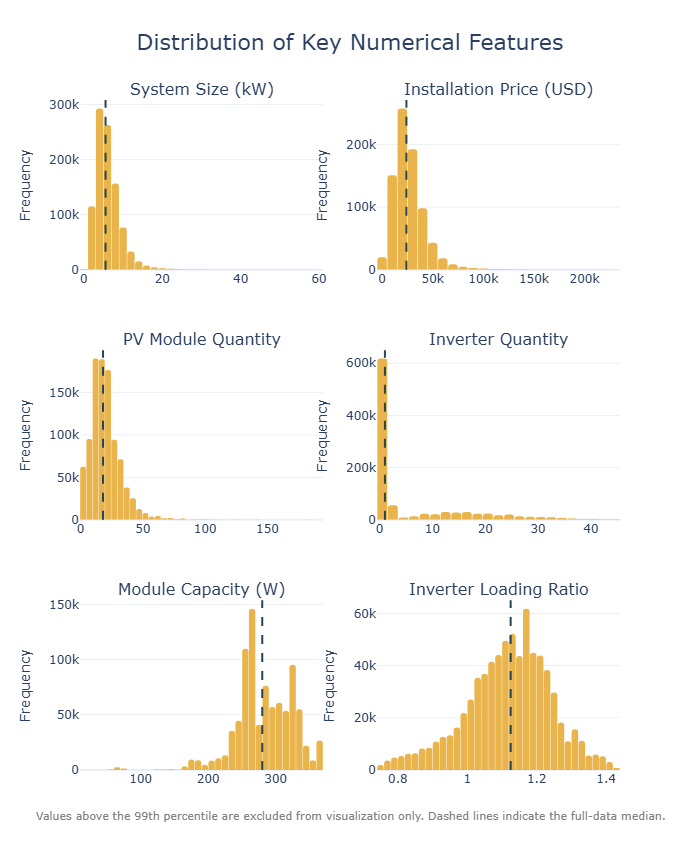

In [13]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

# Select key numerical variables
selected_features = {
    "system_size_DC": "System Size (kW)",
    "total_installed_price": "Installation Price (USD)",
    "module_quantity_1": "PV Module Quantity",
    "inverter_quantity_1": "Inverter Quantity",
    "nameplate_capacity_module_1": "Module Capacity (W)",
    "inverter_loading_ratio": "Inverter Loading Ratio"
}

# Create a 3x2 subplot layout
fig = make_subplots(
    rows=3,
    cols=2,
    subplot_titles=list(selected_features.values()),
    vertical_spacing=0.12,
    horizontal_spacing=0.10
)

for i, (feature, title) in enumerate(selected_features.items()):

    row = i // 2 + 1
    col = i % 2 + 1

    values = df[feature].dropna()

    # Limit visualization to the central 99% of observations
    upper_limit = values.quantile(0.99)
    plot_values = values[values <= upper_limit]

    fig.add_trace(
        go.Histogram(
            x=plot_values,
            nbinsx=40,
            marker_color="#E9B44C",
            name=title,
            showlegend=False
        ),
        row=row,
        col=col
    )

    # Add median reference line
    fig.add_vline(
        x=values.median(),
        line_color="#264653",
        line_dash="dash",
        line_width=2,
        row=row,
        col=col
    )

fig.update_layout(
    title="Distribution of Key Numerical Features",
    title_x=0.5,
    title_font_size=22,
    template="plotly_white",
    height=850,
    bargap=0.06,
    barcornerradius=3,
    font_size=12
)

fig.update_yaxes(title_text="Frequency")

fig.add_annotation(
    text="Values above the 99th percentile are excluded "
         "from visualization only. Dashed lines indicate "
         "the full-data median.",
    xref="paper",
    yref="paper",
    x=0.5,
    y=-0.08,
    showarrow=False,
    font=dict(size=11, color="gray")
)

fig.show(renderer="png")

#### Numerical Variables — Key Findings

- System size, installation price, module quantity, and inverter quantity exhibit right-skewed distributions.
- Module capacity exhibits a multimodal distribution.
- The inverter loading ratio exhibits an approximately bell-shaped distribution, with a median of 1.12.
- Several numerical variables contain extreme values requiring further investigation.

In [14]:
# Generate descriptive statistics for categorical variables
categorical_summary = df.describe(include=["object"]).T

with pd.option_context("display.max_rows", None):
    display(categorical_summary)

,count,unique,top,freq
Variable,,,,
data_provider_1,1000000,3,CA_CPUC,998971
data_provider_2,221982,2,California Public Utilities Commission,146510
system_ID_1,999895,999895,R1194,1
system_ID_2,222098,218662,PGE-SGIP-2006-1409,23
installation_date,1000000,6516,28-Oct-2019 00:00:00,1136
customer_segment,1000000,6,RES,974311
zip_code,999998,2103,95648,6539
city,999999,2672,SAN DIEGO,44933
state,1000000,3,CA,998971


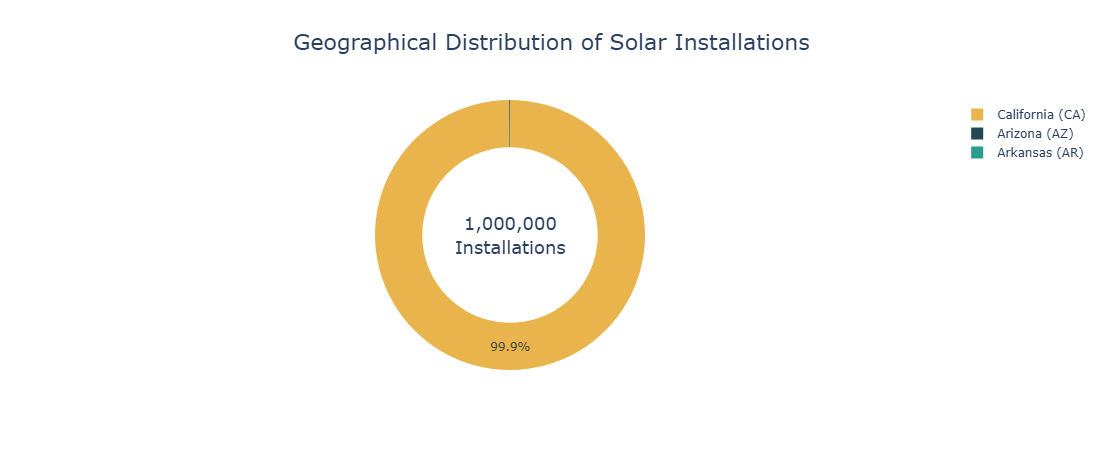

In [15]:
# Calculate geographical distribution
state_summary = df["state"].value_counts().reset_index()
state_summary.columns = ["State", "Count"]
# Replace state abbreviations with full names
state_summary["State"] = state_summary["State"].replace({
    "CA": "California (CA)",
    "AZ": "Arizona (AZ)",
    "AR": "Arkansas (AR)"
})

# Visualize geographical distribution
fig = px.pie(
    state_summary,
    names="State",
    values="Count",
    hole=0.65,
    title="Geographical Distribution of Solar Installations",
    color_discrete_sequence=[
        "#E9B44C", "#264653", "#2A9D8F"
    ],
    template="plotly_white"
)

fig.update_traces(
    textposition="inside",
    textinfo="percent",
    hovertemplate="%{label}<br>Installations: %{value:,}"
                  "<br>Share: %{percent}<extra></extra>"
)

fig.update_layout(
    uniformtext_minsize=12,
    uniformtext_mode="hide"
)

fig.update_layout(
    title_x=0.5,
    title_font_size=22,
    height=450,
    annotations=[
        dict(
            text="1,000,000<br>Installations",
            x=0.5,
            y=0.5,
            font_size=18,
            showarrow=False
        )
    ]
)

fig.show()

In [16]:
# Examine the relationship between data providers and states
pd.crosstab(
    df["data_provider_1"],
    df["state"],
    margins=True
)

state,AR,AZ,CA,All
data_provider_1,,,,
Arizona Public Service,0,924,0,924
Arkansas State Energy Office,105,0,0,105
CA_CPUC,0,0,998971,998971
All,105,924,998971,1000000


In [17]:
# Examine customer segment distribution across states
pd.crosstab(
    df["state"],
    df["customer_segment"],
    margins=True
)

customer_segment,COM,GOV,NON-PROFIT,NON-RES,RES,SCHOOL,All
state,,,,,,,
AR,11,1,1,0,92,0,105
AZ,0,0,0,66,858,0,924
CA,19682,3129,1545,0,973361,1254,998971
All,19693,3130,1546,66,974311,1254,1000000


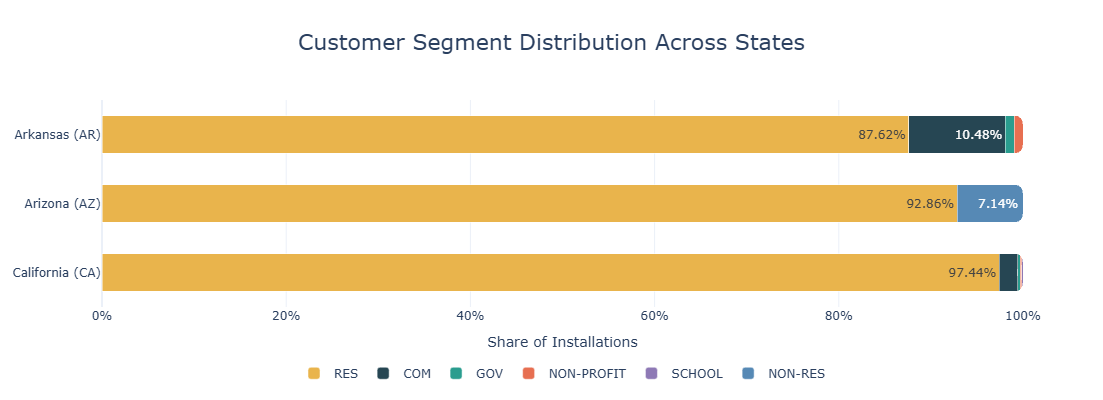

In [18]:
# Calculate customer segment proportions by state
segment_distribution = pd.crosstab(
    df["state"],
    df["customer_segment"],
    normalize="index"
) * 100

# Define state names
segment_distribution = segment_distribution.rename(
    index={
        "CA": "California (CA)",
        "AZ": "Arizona (AZ)",
        "AR": "Arkansas (AR)"
    }
)

# Define segment order
segment_order = [
    "RES", "COM", "GOV",
    "NON-PROFIT", "SCHOOL", "NON-RES"
]

# Define Solar Energy color palette
segment_colors = {
    "RES": "#E9B44C",
    "COM": "#264653",
    "GOV": "#2A9D8F",
    "NON-PROFIT": "#E76F51",
    "SCHOOL": "#8E79B5",
    "NON-RES": "#5689B5"
}

# Create an interactive stacked bar chart
fig = px.bar(
    segment_distribution[segment_order],
    orientation="h",
    barmode="stack",
    color_discrete_map=segment_colors,
    template="plotly_white",
    title="Customer Segment Distribution Across States"
)

fig.update_traces(
    texttemplate="%{x:.2f}%",
    textposition="inside",
    hovertemplate="%{y}<br>Share: %{x:.2f}%"
)

fig.update_layout(
    title_x=0.5,
    title_font_size=22,
    height=400,
    bargap=0.45,
    barcornerradius=8,
    xaxis_title="Share of Installations",
    yaxis_title=None,
    xaxis=dict(range=[0, 100], ticksuffix="%"),
    yaxis=dict(autorange="reversed"),
    legend=dict(
        orientation="h",
        y=-0.25,
        x=0.5,
        xanchor="center",
        title=None
    ),
    uniformtext_minsize=11,
    uniformtext_mode="hide"
)

fig.show()

#### Customer Segment Distribution Across States — Key Findings

- Residential installations dominate across all three states: California (97.44%), Arizona (92.86%), and Arkansas (87.62%).
- Differences in customer segment labels across states support the consolidation into two classes: RES and NON-RES.
- Substantial differences in sample sizes across states limit direct geographical comparisons.
- Geographical and data source characteristics may introduce model bias.

### 1.2.4 Target Variable Analysis

This section examines the distribution of the target variable, customer_segment, to identify class imbalance and evaluate its implications for the classification task.

The original customer categories are analyzed before their consolidation into a binary classification target.

In [19]:
# Calculate target variable distribution
target_summary = df["customer_segment"].value_counts().to_frame(
    name="Count"
)

target_summary["Percentage"] = (
    target_summary["Count"] / len(df) * 100
)

target_summary.round(4)

,Count,Percentage
customer_segment,,
RES,974311,97.4311
COM,19693,1.9693
GOV,3130,0.3130
NON-PROFIT,1546,0.1546
SCHOOL,1254,0.1254
NON-RES,66,0.0066


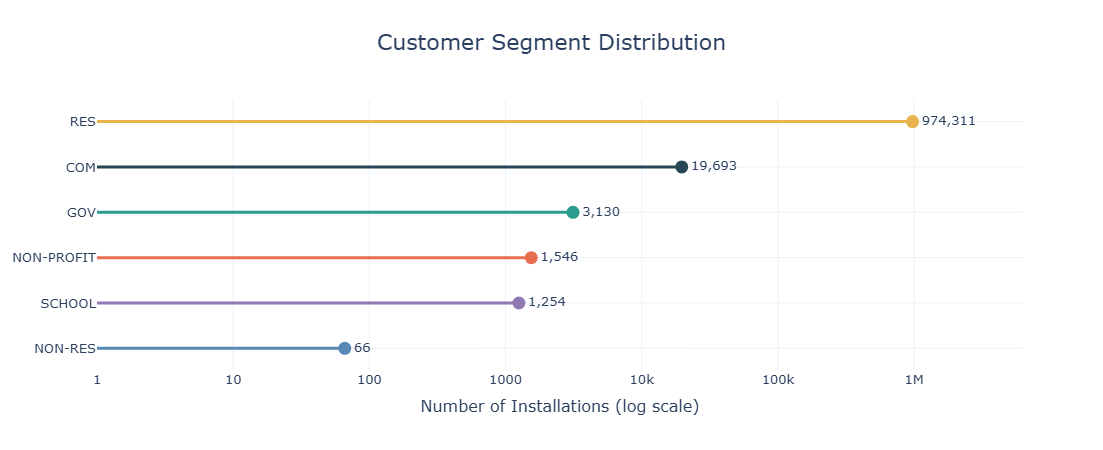

In [20]:
import plotly.graph_objects as go

fig = go.Figure()

for segment, row in target_summary.iterrows():

    count = int(row["Count"])
    color = segment_colors[segment]

    fig.add_trace(go.Scatter(
        x=[1, count],
        y=[segment, segment],
        mode="lines",
        line=dict(color=color, width=3),
        hoverinfo="skip",
        showlegend=False
    ))

    fig.add_trace(go.Scatter(
        x=[count],
        y=[segment],
        mode="markers+text",
        marker=dict(size=13, color=color),
        text=[f"{count:,}"],
        textposition="middle right",
        hovertemplate=(
            f"Segment: {segment}<br>"
            f"Installations: {count:,}<br>"
            f"Share: {row['Percentage']:.4f}%"
            "<extra></extra>"
        ),
        showlegend=False
    ))

fig.update_layout(
    title="Customer Segment Distribution",
    title_x=0.5,
    title_font_size=22,
    template="plotly_white",
    height=450,
    font_size=13,
    xaxis=dict(
        type="log",
        title="Number of Installations (log scale)",
        range=[0, 6.8],
        dtick=1
    ),
    yaxis=dict(
        title=None,
        autorange="reversed"
    )
)

fig.show()

#### Target Variable — Key Findings

- The target variable contains six original customer segments with no missing values.
- Residential installations account for 97.43% of observations, commercial installations for 1.97%, and the remaining categories for approximately 0.60%.
- The target variable exhibits severe class imbalance.
- Consolidating the original categories into RES and NON-RES simplifies the classification task but does not resolve class imbalance.

In [21]:
# Examine the expected binary target distribution
binary_target_summary = (
    df["customer_segment"]
    .replace({
        "COM": "NON-RES",
        "GOV": "NON-RES",
        "NON-PROFIT": "NON-RES",
        "SCHOOL": "NON-RES"
    })
    .value_counts()
    .to_frame(name="Count")
)

binary_target_summary["Percentage"] = (
    binary_target_summary["Count"] / len(df) * 100
)

binary_target_summary.round(4)

,Count,Percentage
customer_segment,,
RES,974311,97.4311
NON-RES,25689,2.5689


In [22]:
# Calculate the class imbalance ratio
imbalance_ratio = (
    binary_target_summary.loc["RES", "Count"] /
    binary_target_summary.loc["NON-RES", "Count"]
)

print(f"Class Imbalance Ratio: {imbalance_ratio:.2f}:1")

Class Imbalance Ratio: 37.93:1


#### Class Imbalance — Implications for Modeling

After consolidating the original customer segments:

- Residential (RES): 97.43%
- Non-Residential (NON-RES): 2.57%
- Class imbalance ratio: 37.93:1

A classifier that always predicts the majority class would achieve 97.43% accuracy while failing to identify any non-residential installations. Therefore, accuracy alone is insufficient for model evaluation.

The following strategies should be considered:

- Stratified train-test splitting.
- Class weighting.
- Minority-class Precision, Recall, and F1-score.
- Balanced Accuracy and Average Precision.
- Confusion matrix analysis.

## 1.3 Data Quality Assessment

The purpose of this section is to assess the quality and reliability of the dataset before data preparation and machine learning modeling.

The assessment focuses on missing values, duplicate records, constant and near-constant variables, data type consistency, and potential anomalies.

Particular attention is given to data quality issues
that may disproportionately affect the minority
customer segment (NON-RES).

### 1.3.1 Missing Values Analysis

In [23]:
# Calculate missing values for each variable
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage (%)": df.isna().mean() * 100
})

# Retain variables with missing values and sort by percentage
missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing Percentage (%)", ascending=False)

missing_summary.index.name = "Variable"

display(missing_summary.round(2))

,Missing Count,Missing Percentage (%)
Variable,,
technology_module_3,1000000,100.00
solar_storage_hybrid_inverter_3,1000000,100.00
module_quantity_3,999630,99.96
module_manufacturer_3,998736,99.87
module_model_3,998736,99.87
...,...,...
additional_modules,1029,0.10
additional_inverters,1029,0.10
system_ID_1,105,0.01


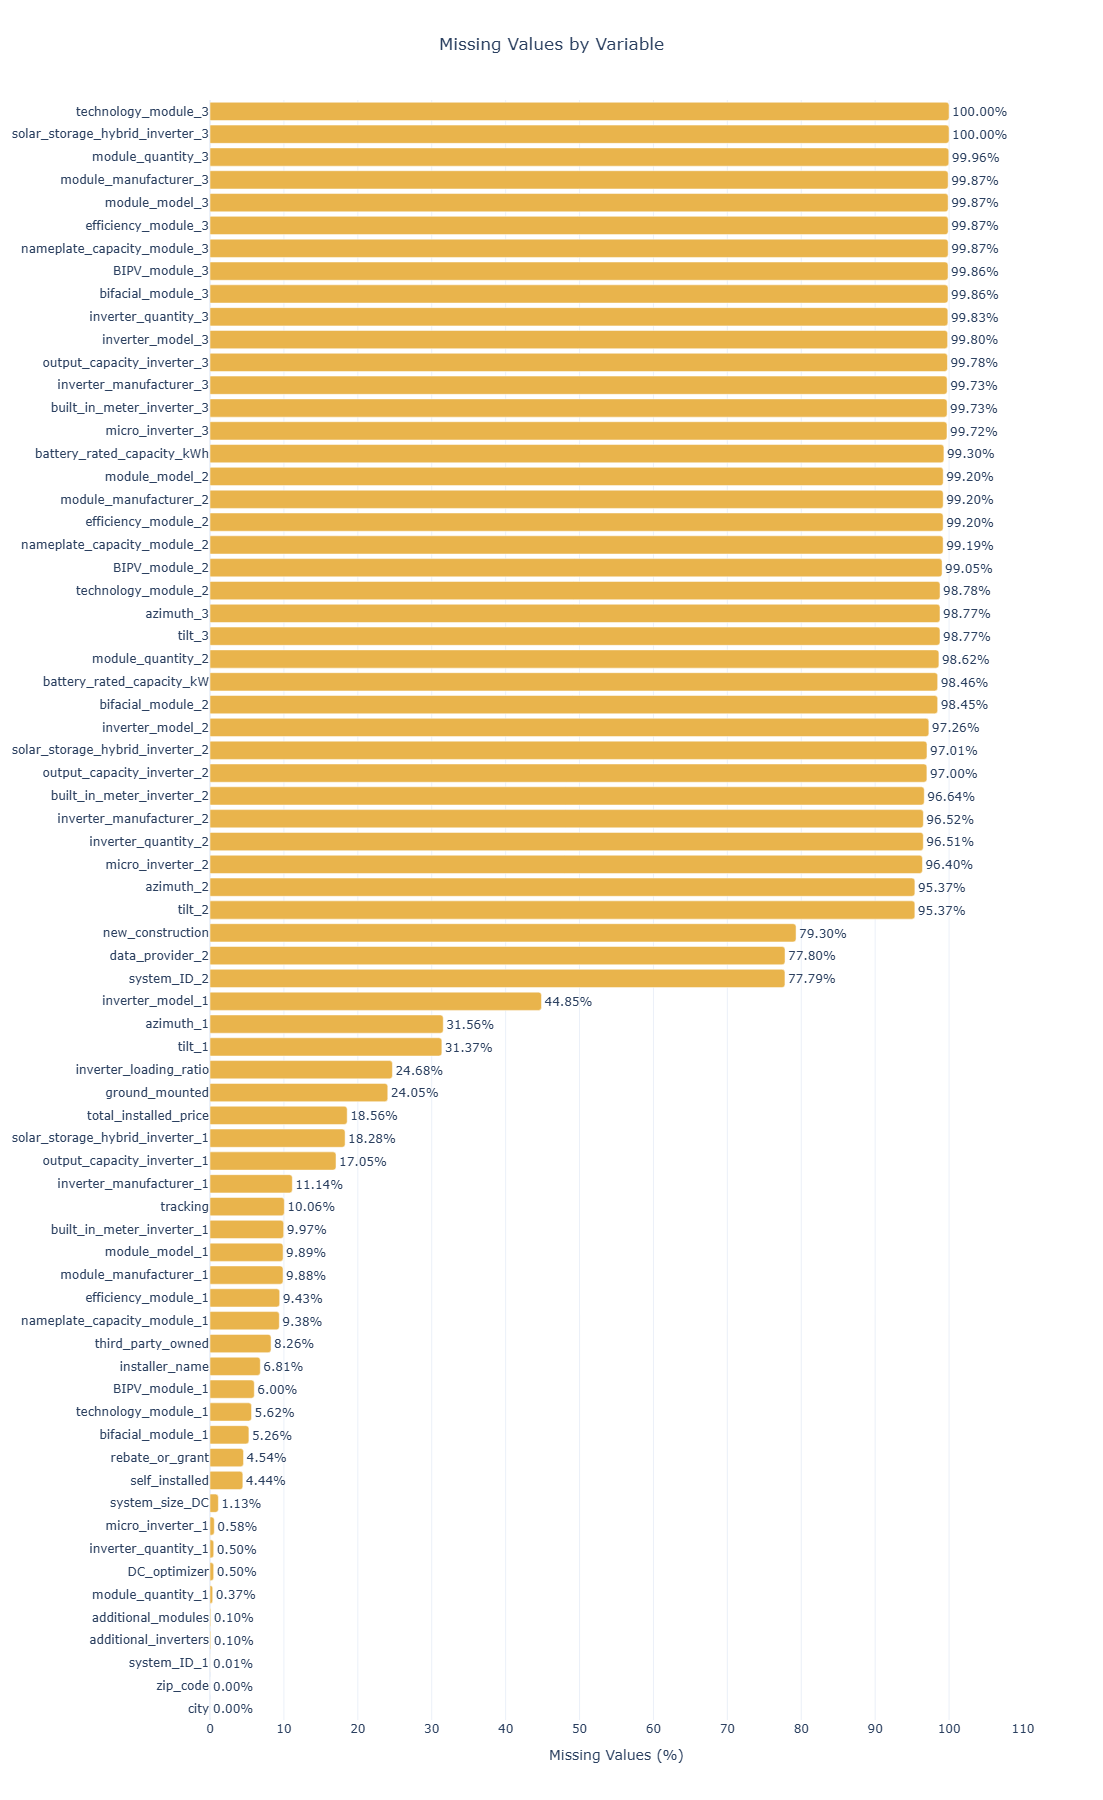

In [24]:
# Visualize missing values by variable
fig = px.bar(
    missing_summary.reset_index(),
    x="Missing Percentage (%)",
    y="Variable",
    orientation="h",
    text="Missing Percentage (%)",
    title="Missing Values by Variable",
    color_discrete_sequence=["#E9B44C"]
)

fig.update_traces(
    texttemplate="%{x:.2f}%",
    textposition="outside",
    cliponaxis=False
)

fig.update_layout(
    template="plotly_white",
    height=1800,
    bargap=0.2,
    barcornerradius=3,
    font_size=12,
    xaxis_title="Missing Values (%)",
    yaxis_title=None,
    title_x=0.5
)

fig.update_yaxes(autorange="reversed")
fig.update_xaxes(range=[0, 110], dtick=10)

fig.show()

In [25]:
# Calculate missing percentages for all variables
missing_pct = df.isna().mean() * 100

# Define missingness categories
missing_levels = [
    "No missing values",
    "Very low (>0–5%)",
    "Low (>5–20%)",
    "Moderate (>20–50%)",
    "High (>50–90%)",
    "Very high (>90–<100%)",
    "Completely missing (100%)"
]

# Group variables by missingness level
missing_distribution = pd.Series([
    (missing_pct == 0).sum(),
    ((missing_pct > 0) & (missing_pct <= 5)).sum(),
    ((missing_pct > 5) & (missing_pct <= 20)).sum(),
    ((missing_pct > 20) & (missing_pct <= 50)).sum(),
    ((missing_pct > 50) & (missing_pct <= 90)).sum(),
    ((missing_pct > 90) & (missing_pct < 100)).sum(),
    (missing_pct == 100).sum()
], index=missing_levels, name="Variable Count")

missing_distribution.index.name = "Missingness Level"

display(missing_distribution.to_frame())

,Variable Count
Missingness Level,
No missing values,7
Very low (>0–5%),12
Low (>5–20%),15
Moderate (>20–50%),5
High (>50–90%),3
Very high (>90–<100%),34
Completely missing (100%),2


In [26]:
# Combine missingness information with variable categories
missing_by_category = data_description[["Category"]].copy()

missing_by_category["Missing Percentage (%)"] = missing_pct

# Summarize missingness by variable category
category_missing_summary = (
    missing_by_category
    .groupby("Category")
    .agg(
        Variable_Count=("Missing Percentage (%)", "size"),
        Mean_Missing_Pct=("Missing Percentage (%)", "mean"),
        Median_Missing_Pct=("Missing Percentage (%)", "median"),
        Max_Missing_Pct=("Missing Percentage (%)", "max")
    )
    .sort_values("Mean_Missing_Pct", ascending=False)
)

display(category_missing_summary.round(2))

,Variable_Count,Mean_Missing_Pct,Median_Missing_Pct,Max_Missing_Pct
Category,,,,
Battery Storage Characteristics,2,98.88,98.88,99.30
PV Array Orientation,6,75.20,95.37,98.77
PV Module Characteristics,25,65.87,99.05,100.00
Inverter and DC Optimizer Characteristics,24,62.65,96.51,100.00
Data Sources and System Identifiers,4,38.90,38.90,77.80
System Configuration,6,19.09,5.59,79.30
Financial and Ownership Information,3,10.45,8.26,18.56
Installer Information,2,5.63,5.63,6.81
Geographic Information,4,0.00,0.00,0.00


#### Missingness by Customer Segment

Given the substantial class imbalance, overall missingness rates may not accurately reflect data availability within the minority customer segment.

This analysis compares missing value percentages between residential (RES) and non-residential (NON-RES) installations to identify potential differences in data completeness across the two target classes.

In [27]:
# Create temporary binary target labels
binary_segment = df["customer_segment"].replace({
    "COM": "NON-RES",
    "GOV": "NON-RES",
    "NON-PROFIT": "NON-RES",
    "SCHOOL": "NON-RES"
})

# Calculate missingness percentages within each customer segment
segment_missingness = (
    df.drop(columns="customer_segment")
    .isna()
    .groupby(binary_segment)
    .mean()
    .T * 100
)

segment_missingness = segment_missingness[["RES", "NON-RES"]]

# Calculate signed and absolute differences in percentage points
segment_missingness["Difference (pp)"] = (
    segment_missingness["NON-RES"] -
    segment_missingness["RES"]
)

segment_missingness["Absolute Difference (pp)"] = (
    segment_missingness["Difference (pp)"].abs()
)

# Sort variables by the magnitude of missingness differences
segment_missingness = segment_missingness.sort_values(
    "Absolute Difference (pp)", ascending=False
)

segment_missingness.index.name = "Variable"
segment_missingness.columns.name = None

display(segment_missingness.head(20).round(2))

,RES,NON-RES,Difference (pp),Absolute Difference (pp)
Variable,,,,
new_construction,78.78,98.88,20.10,20.10
output_capacity_inverter_1,16.66,31.78,15.12,15.12
inverter_loading_ratio,24.29,39.36,15.06,15.06
inverter_quantity_2,96.87,83.00,-13.87,13.87
micro_inverter_2,96.74,83.45,-13.29,13.29
inverter_manufacturer_2,96.85,83.89,-12.96,12.96
built_in_meter_inverter_2,96.95,85.00,-11.94,11.94
solar_storage_hybrid_inverter_2,97.30,85.96,-11.35,11.35
output_capacity_inverter_2,97.25,87.31,-9.94,9.94


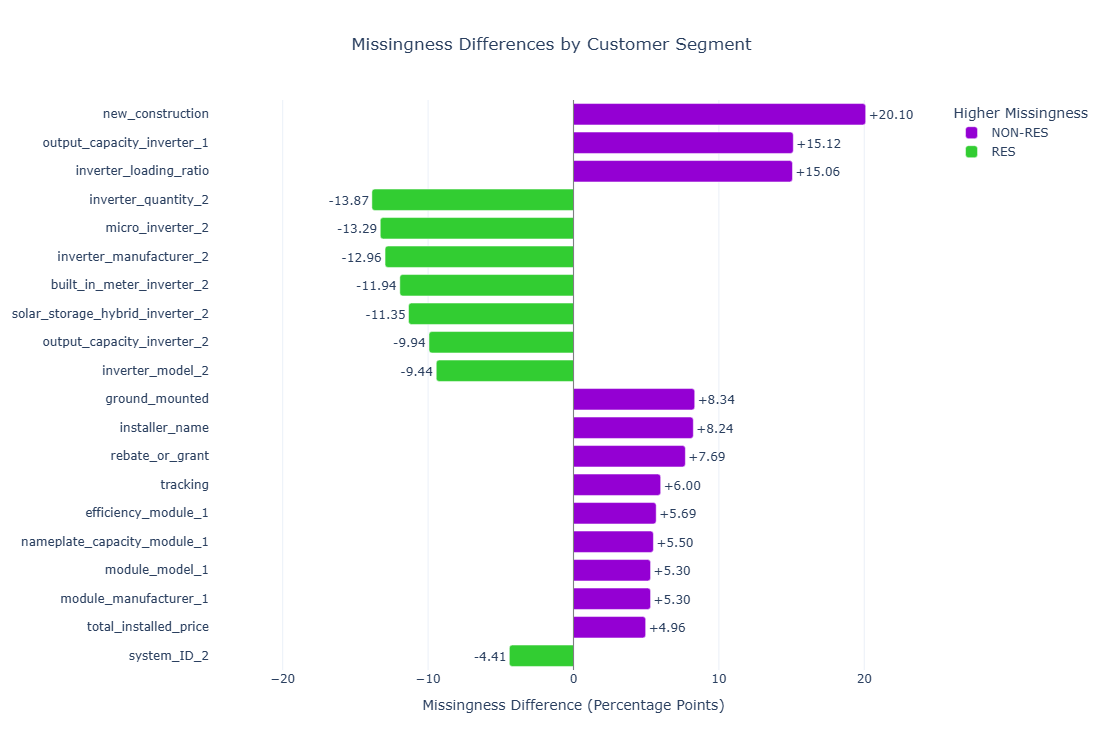

In [28]:
# Select the 20 variables with the largest missingness differences
top_missingness = segment_missingness.head(20).reset_index()

# Identify which customer segment has higher missingness
top_missingness["Higher Missingness"] = np.where(
    top_missingness["Difference (pp)"] > 0,
    "NON-RES",
    "RES"
)

# Format bar labels to two decimal places
top_missingness["Label"] = top_missingness["Difference (pp)"].map(
    lambda x: f"{x:+.2f}"
)

# Create a diverging bar chart
fig = px.bar(
    top_missingness,
    x="Difference (pp)",
    y="Variable",
    color="Higher Missingness",
    orientation="h",
    text="Label",
    title="Missingness Differences by Customer Segment",
    color_discrete_map={
        "RES": "limegreen",
        "NON-RES": "darkviolet"
    },
    hover_data=["RES", "NON-RES"]
)

fig.update_traces(
    texttemplate="%{text}",
    textposition="outside",
    cliponaxis=False
)

fig.update_layout(
    template="plotly_white",
    height=750,
    bargap=0.25,
    barcornerradius=3,
    font_size=12,
    title_x=0.5,
    xaxis_title="Missingness Difference (Percentage Points)",
    yaxis_title=None,
    legend_title="Higher Missingness"
)

fig.update_yaxes(
    categoryorder="array",
    categoryarray=top_missingness["Variable"].tolist(),
    autorange="reversed"
)

fig.update_xaxes(range=[-25, 25])

fig.add_vline(
    x=0,
    line_width=1,
    line_color="gray"
)

fig.show()

#### Missingness by Customer Segment — Key Findings

- The largest missingness difference is observed in `new_construction` (20.10 percentage points).
- Primary inverter output capacity and inverter loading ratio exhibit higher missingness in the NON-RES segment.
- Secondary inverter characteristics are more frequently available in the NON-RES segment.
- Class-specific missingness patterns may provide predictive information but require careful evaluation to avoid target leakage.

#### Missing Values Analysis — Overall Summary

- 71 out of 78 variables (91.03%) contain missing values.
- 36 variables (46.15%) have missingness rates above 90%, including two completely missing variables.
- Missingness is predominantly concentrated in battery storage, PV array orientation, module, and inverter characteristics.
- Data availability differs between customer segments and should be considered during data preparation and modeling.

### 1.3.2 Duplicate Records Analysis

The purpose of this section is to identify exact duplicate records, repeated system identifiers, and potential duplicate installation records.

Duplicate records may introduce bias into the analysis and lead to overly optimistic model evaluation if the same installation appears in both training and test sets.

No records are removed at this stage.

#### Exact Duplicates

In [29]:
# Identify exact duplicate records across all variables
duplicate_count = df.duplicated().sum()

# Calculate the percentage of exact duplicate records
duplicate_percentage = duplicate_count / len(df) * 100

# Summarize the results
duplicate_summary = pd.DataFrame({
    "Total Records": [len(df)],
    "Exact Duplicate Records": [duplicate_count],
    "Duplicate Records (%)": [duplicate_percentage]
})

display(duplicate_summary.round(4))

,Total Records,Exact Duplicate Records,Duplicate Records (%)
0,1000000,0,0.0


#### Duplicate System Identifiers

System identifiers are examined to determine whether multiple records share the same installation identifier.

Missing identifiers are excluded from this analysis. Repeated identifiers do not necessarily indicate duplicate installations.

In [30]:
# Examine repeated system identifiers
identifier_results = []

for col in ["system_ID_1", "system_ID_2"]:

    ids = df[col].dropna()
    id_counts = ids.value_counts()
    repeated_ids = id_counts[id_counts > 1]

    identifier_results.append({
        "Identifier": col,
        "Non-Missing Count": len(ids),
        "Missing Count": df[col].isna().sum(),
        "Unique Identifiers": ids.nunique(),
        "Repeated Identifiers": len(repeated_ids),
        "Records with Repeated IDs": repeated_ids.sum(),
        "Duplicate Occurrences": ids.duplicated().sum()
    })

identifier_summary = pd.DataFrame(
    identifier_results
).set_index("Identifier")

display(identifier_summary)

,Non-Missing Count,Missing Count,Unique Identifiers,Repeated Identifiers,Records with Repeated IDs,Duplicate Occurrences
Identifier,,,,,,
system_ID_1,999895,105,999895,0,0,0
system_ID_2,222098,777902,218662,3254,6690,3436


#### Identifier Uniqueness by Data Provider

Repeated secondary system identifiers are examined in combination with their associated data providers to assess whether identifier repetition may result from provider-specific identification systems.

In [31]:
# Select records with available secondary system identifiers
secondary_ids = df.loc[
    df["system_ID_2"].notna(),
    ["data_provider_2", "system_ID_2"]
]

# Exclude records with missing provider information
provider_ids = secondary_ids.dropna(
    subset=["data_provider_2"]
)

# Compare identifier repetition before and after
# accounting for data providers
provider_duplicate_summary = pd.DataFrame({
    "Metric": [
        "Records with Missing Provider",
        "Records Analyzed",
        "Duplicate Occurrences (ID Only)",
        "Duplicate Occurrences (Provider + ID)"
    ],
    "Count": [
        secondary_ids["data_provider_2"].isna().sum(),
        len(provider_ids),
        provider_ids.duplicated(
            subset=["system_ID_2"]
        ).sum(),
        provider_ids.duplicated(
            subset=["data_provider_2", "system_ID_2"]
        ).sum()
    ]
})

display(provider_duplicate_summary)

,Metric,Count
0,Records with Missing Provider,116
1,Records Analyzed,221982
2,Duplicate Occurrences (ID Only),3436
3,Duplicate Occurrences (Provider + ID),895


#### Within-Provider Duplicate Investigation

Records sharing the same secondary data provider and system identifier are examined in greater detail.

The analysis compares installation dates, geographical locations, system capacities, customer segments, and system configuration characteristics to identify potential duplicate installations and legitimate repeated observations.

In [32]:
# Define the composite identifier
id_columns = ["data_provider_2", "system_ID_2"]

# Select records with complete composite identifiers
valid_ids = df.dropna(subset=id_columns)

# Identify all records sharing the same composite identifier
repeated_records = valid_ids.loc[
    valid_ids.duplicated(subset=id_columns, keep=False)
]

# Select installation characteristics for comparison
comparison_features = [
    "installation_date",
    "zip_code",
    "system_size_DC",
    "customer_segment",
    "expansion_system",
    "multiple_phase_system"
]

# Count distinct non-missing values within each repeated ID group
group_variability = (
    repeated_records
    .groupby(id_columns)[comparison_features]
    .nunique(dropna=True)
)

# Summarize consistency across repeated identifier groups
consistency_summary = pd.DataFrame({
    "No Available Values": (group_variability == 0).sum(),
    "One Distinct Value": (group_variability == 1).sum(),
    "Multiple Distinct Values": (group_variability > 1).sum()
})

consistency_summary.index.name = "Variable"

print(f"Records with repeated composite IDs: {len(repeated_records):,}")
print(f"Repeated composite ID groups: {len(group_variability):,}")

display(consistency_summary)

Records with repeated composite IDs: 1,622
Repeated composite ID groups: 727


,No Available Values,One Distinct Value,Multiple Distinct Values
Variable,,,
installation_date,0,727,0
zip_code,0,727,0
system_size_DC,0,725,2
customer_segment,0,720,7
expansion_system,0,727,0
multiple_phase_system,0,727,0


#### Target Label Consistency

Repeated composite identifier groups with conflicting customer segment labels are examined to determine whether these inconsistencies persist after binary target transformation.

In [33]:
# Select groups with conflicting original target labels
conflicting_groups = group_variability.loc[
    group_variability["customer_segment"] > 1
].index

# Extract records belonging to conflicting groups
conflicting_records = (
    repeated_records
    .set_index(id_columns)
    .loc[conflicting_groups]
    .reset_index()
    .copy()
)

# Create temporary binary target labels
conflicting_records["Binary Segment"] = (
    conflicting_records["customer_segment"].replace({
        "COM": "NON-RES",
        "GOV": "NON-RES",
        "NON-PROFIT": "NON-RES",
        "SCHOOL": "NON-RES"
    })
)

# Compare original and binary target labels
target_conflict_summary = (
    conflicting_records
    .groupby(id_columns)
    .agg(
        Record_Count=("customer_segment", "size"),
        Original_Labels=("customer_segment",
                         lambda x: sorted(x.unique())),
        Binary_Labels=("Binary Segment",
                       lambda x: sorted(x.unique())),
        Binary_Label_Count=("Binary Segment", "nunique")
    )
)

target_conflict_summary["Binary Conflict"] = (
    target_conflict_summary["Binary_Label_Count"] > 1
)

display(target_conflict_summary)

print(
    "Groups with binary target conflicts:",
    target_conflict_summary["Binary Conflict"].sum()
)

Record_Count  \
data_provider_2                        system_ID_2                        
California Energy Commission           13519                          2   
                                       4534                           2   
                                       4752                           2   
                                       8070                           2   
California Public Utilities Commission PGE-SGIP-2002-0257             2   
                                       PGE-SGIP-2004-0624             2   
                                       PGE-SGIP-2006-1560             4   

                                                          Original_Labels  \
data_provider_2                        system_ID_2                          
California Energy Commission           13519                   [COM, RES]   
                                       4534                    [COM, RES]   
                                       4752                    [COM, RES]   
                                       8070                    [COM, RES]   
California Public Utilities Commission PGE-SGIP-2002-0257      [COM, RES]   
                                       PGE-SGIP-2004-0624      [COM, RES]   
                                       PGE-SGIP-2006-1560      [COM, RES]   

                                                            Binary_Labels  \
data_provider_2                        system_ID_2                          
California Energy Commission           13519               [NON-RES, RES]   
                                       4534                [NON-RES, RES]   
                                       4752                [NON-RES, RES]   
                                       8070                [NON-RES, RES]   
California Public Utilities Commission PGE-SGIP-2002-0257  [NON-RES, RES]   
                                       PGE-SGIP-2004-0624  [NON-RES, RES]   
                                       PGE-SGIP-2006-1560  [NON-RES, RES]   

                                                           Binary_Label_Count  \
data_provider_2                        system_ID_2                              
California Energy Commission           13519                                2   
                                       4534                                 2   
                                       4752                                 2   
                                       8070                                 2   
California Public Utilities Commission PGE-SGIP-2002-0257                   2   
                                       PGE-SGIP-2004-0624                   2   
                                       PGE-SGIP-2006-1560                   2   

                                                           Binary Conflict  
data_provider_2                        system_ID_2                          
California Energy Commission           13519                          True  
                                       4534                           True  
                                       4752                           True  
                                       8070                           True  
California Public Utilities Commission PGE-SGIP-2002-0257             True  
                                       PGE-SGIP-2004-0624             True  
                                       PGE-SGIP-2006-1560             True

Groups with binary target conflicts: 7


#### Potential Duplicate Installations

Potential duplicate installations are identified by comparing key installation characteristics independently of system identifiers.   
Matching characteristics indicate potential duplicates but do not necessarily confirm that the records represent the same physical installation.

In [34]:
# Define characteristics for potential duplicate detection
installation_features = [
    "installation_date",
    "state",
    "zip_code",
    "system_size_DC",
    "installer_name",
    "module_quantity_1",
    "module_model_1",
    "inverter_quantity_1",
    "inverter_model_1"
]

# Exclude records with missing comparison characteristics
complete_installations = df.dropna(
    subset=installation_features
)

# Identify records with matching installation characteristics
potential_duplicates = complete_installations.loc[
    complete_installations.duplicated(
        subset=installation_features,
        keep=False
    )
]

# Count groups with matching installation characteristics
potential_duplicate_groups = (
    potential_duplicates
    .groupby(installation_features)
    .size()
)

# Summarize the results
potential_duplicate_summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Records Analyzed",
        "Records Excluded Due to Missing Values",
        "Records with Matching Characteristics",
        "Potential Duplicate Groups",
        "Duplicate Occurrences"
    ],
    "Count": [
        len(df),
        len(complete_installations),
        len(df) - len(complete_installations),
        len(potential_duplicates),
        len(potential_duplicate_groups),
        len(potential_duplicates) - len(potential_duplicate_groups)
    ]
})

display(potential_duplicate_summary)

,Metric,Count
0,Total Records,1000000
1,Records Analyzed,474531
2,Records Excluded Due to Missing Values,525469
3,Records with Matching Characteristics,20877
4,Potential Duplicate Groups,6957
5,Duplicate Occurrences,13920


#### Potential Duplicate Installations by Customer Segment

This analysis evaluates the distribution of potential duplicate installations across residential (RES) and non-residential (NON-RES) customer segments.

The objective is to assess differences in analysis coverage, potential duplicate frequency, and target label consistency between the two classes.

In [35]:
# Define binary customer segments without modifying the original dataset
binary_segment = df["customer_segment"].replace({
    "COM": "NON-RES",
    "GOV": "NON-RES",
    "NON-PROFIT": "NON-RES",
    "SCHOOL": "NON-RES"
})

# Summarize potential duplicates by customer segment
duplicate_segment_summary = pd.DataFrame({
    "Total Records": binary_segment.value_counts(),
    "Records Analyzed": binary_segment.loc[
        complete_installations.index
    ].value_counts(),
    "Records with Matching Characteristics": binary_segment.loc[
        potential_duplicates.index
    ].value_counts()
}).fillna(0).astype(int)

# Calculate analysis coverage within each segment
duplicate_segment_summary["Analysis Coverage (%)"] = (
    duplicate_segment_summary["Records Analyzed"]
    / duplicate_segment_summary["Total Records"] * 100
)

# Calculate matching record frequency within each analyzed segment
duplicate_segment_summary["Matching Records (%)"] = (
    duplicate_segment_summary["Records with Matching Characteristics"]
    / duplicate_segment_summary["Records Analyzed"] * 100
)

duplicate_segment_summary.index.name = "Customer Segment"

display(duplicate_segment_summary.round(2))

,Total Records,Records Analyzed,Records with Matching Characteristics,Analysis Coverage (%),Matching Records (%)
Customer Segment,,,,,
RES,974311,464059,20191,47.63,4.35
NON-RES,25689,10472,686,40.76,6.55


#### Duplicate Records Analysis — Key Findings

- No exact duplicate records were identified, and all non-missing primary system identifiers are unique.
- Repeated secondary identifier occurrences decrease from 3,436 to 895 when accounting for data providers.
- Seven repeated composite identifier groups contain conflicting binary target labels.
- Matching installation characteristics were identified in 4.40% of the analyzed subset, which covers 47.45% of the dataset.
- Matching records are more frequent among analyzed NON-RES installations (6.55%) than RES installations (4.35%).
- Repeated identifiers and matching characteristics do not provide sufficient evidence for automatic record removal.

No records were removed or modified at this stage.

### 1.3.3 Constant and Near-Constant Variables

This analysis identifies variables with no or limited variability that may provide little predictive information.

Variables are classified as:

- **Completely missing:** no observed values.
- **Constant:** only one unique observed value.
- **Near-constant:** the most frequent value accounts for at least 99% of non-missing observations.

Given the class imbalance, low variability alone does not justify feature removal.   
No variables are removed at this stage.

In [36]:
# Assess variability across all variables
variability_results = []

for col in df.columns:

    values = df[col].dropna()
    unique_count = values.nunique()

    dominant_value = None
    dominant_percentage = np.nan

    if unique_count == 0:
        status = "Completely Missing"

    else:
        frequencies = values.value_counts()
        dominant_value = frequencies.index[0]
        dominant_percentage = frequencies.iloc[0] / len(values) * 100

        if unique_count == 1:
            status = "Constant"
        elif dominant_percentage >= 99:
            status = "Near-Constant"
        else:
            status = "Variable"

    variability_results.append({
        "Variable": col,
        "Non-Missing Count": len(values),
        "Unique Values": unique_count,
        "Dominant Value": dominant_value,
        "Dominant Value (%)": dominant_percentage,
        "Status": status
    })

variability_summary = pd.DataFrame(
    variability_results
).set_index("Variable")

# Display variables with no or limited variability
low_variability = variability_summary[
    variability_summary["Status"] != "Variable"
].sort_values("Dominant Value (%)", ascending=False)

display(low_variability.round(2))

,Non-Missing Count,Unique Values,Dominant Value,Dominant Value (%),Status
Variable,,,,,
bifacial_module_3,1429,1,0.0,100.00,Constant
additional_modules,998971,2,0.0,99.99,Near-Constant
additional_inverters,998971,2,0.0,99.97,Near-Constant
bifacial_module_2,15466,2,0.0,99.96,Near-Constant
bifacial_module_1,947354,2,0.0,99.94,Near-Constant
data_provider_1,1000000,3,CA_CPUC,99.90,Near-Constant
state,1000000,3,CA,99.90,Near-Constant
solar_storage_hybrid_inverter_1,817208,2,0.0,99.59,Near-Constant
BIPV_module_1,940045,2,0.0,99.55,Near-Constant


#### Constant and Near-Constant Variables — Key Findings

- Two variables are completely missing, one is constant, and thirteen are near-constant.
- The low variability of `state` and `data_provider_1` reflects geographical and data source concentration.
- Rare feature values and missingness patterns may still provide predictive information for the minority class.
- Low variability alone does not justify automatic feature removal.

### 1.3.4 Data Type Validation

This analysis evaluates whether the assigned data types are appropriate for the semantic meaning of each variable.

Particular attention is given to:

- Date and time variables.
- System identifiers and ZIP codes.
- Numerical and categorical variables.
- Binary indicators.

Potential data type inconsistencies are identified for further consideration during data preparation.   
No data types are modified at this stage.

In [37]:
# Select variables requiring particular attention
validation_features = [
    "installation_date",
    "system_ID_1",
    "system_ID_2",
    "zip_code",
    "customer_segment",
    "expansion_system",
    "multiple_phase_system",
    "new_construction",
    "tracking",
    "ground_mounted",
    "third_party_owned",
    "self_installed"
]

# Inspect data types and sample values
dtype_validation = pd.DataFrame({
    "Data Type": df[validation_features].dtypes.astype(str),
    "Unique Values": df[validation_features].nunique(),
    "Sample Values": [
        df[col].dropna().unique()[:5].tolist()
        for col in validation_features
    ]
})

dtype_validation.index.name = "Variable"

display(dtype_validation)

,Data Type,Unique Values,Sample Values
Variable,,,
installation_date,object,6516,"[29-Apr-2010 00:00:00, 26-Apr-2010 00:00:00, 2..."
system_ID_1,object,999895,"[SCE-INT-NST-121948, SDGE-INT-231639, PGE-INT-..."
system_ID_2,object,218662,"[NS004SCJ, 140337, 149984, NS005B2B, NS005B5I]"
zip_code,object,2103,"[71953, 72641, 71801, 71909, 72636]"
customer_segment,object,6,"[RES, NON-PROFIT, COM, GOV, SCHOOL]"
expansion_system,int64,2,"[0, 1]"
multiple_phase_system,int64,2,"[0, 1]"
new_construction,float64,2,"[1.0, 0.0]"
tracking,float64,2,"[0.0, 1.0]"


#### Data Type Validation — Key Findings

- `installation_date` is stored as an object rather than a datetime variable.
- System identifiers and ZIP codes should be treated as identifiers rather than numerical measurements.
- The target variable requires transformation for binary classification.
- All seven inspected binary indicators contain valid observed values (0 and 1).

### 1.3.5 Outliers and Data Anomalies

This analysis identifies extreme numerical values and potential data anomalies.   
Statistical outliers are distinguished from potentially invalid observations, as extreme values may represent legitimate non-residential installations.

The analysis focuses on:

- Statistical outlier detection.
- Domain-based validity checks.
- Outlier distribution across customer segments.

In [38]:
# Select key numerical variables for outlier analysis
outlier_features = [
    "system_size_DC",
    "total_installed_price",
    "module_quantity_1",
    "inverter_quantity_1",
    "nameplate_capacity_module_1",
    "inverter_loading_ratio"
]

outlier_results = []

# Identify statistical outliers using the IQR method
for col in outlier_features:

    values = df[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    lower_outliers = (values < lower_bound).sum()
    upper_outliers = (values > upper_bound).sum()

    total_outliers = lower_outliers + upper_outliers

    outlier_results.append({
        "Variable": col,
        "Non-Missing Count": len(values),
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Lower Outliers": lower_outliers,
        "Upper Outliers": upper_outliers,
        "Total Outliers": total_outliers,
        "Outliers (%)": total_outliers / len(values) * 100
    })

outlier_summary = pd.DataFrame(
    outlier_results
).set_index("Variable")

display(outlier_summary.round(2))

,Non-Missing Count,Q1,Q3,IQR,Lower Bound,Upper Bound,Lower Outliers,Upper Outliers,Total Outliers,Outliers (%)
Variable,,,,,,,,,,
system_size_DC,988692,3.92,7.75,3.83,-1.82,13.49,0,44878,44878,4.54
total_installed_price,814364,16282.00,34249.95,17967.95,-10669.92,61201.87,0,38469,38469,4.72
module_quantity_1,996328,12.00,26.00,14.00,-9.00,47.00,0,47516,47516,4.77
inverter_quantity_1,994951,1.00,12.00,11.00,-15.50,28.50,0,57896,57896,5.82
nameplate_capacity_module_1,906207,255.00,315.00,60.00,165.00,405.00,6390,1225,7615,0.84
inverter_loading_ratio,753185,1.04,1.20,0.16,0.80,1.45,9976,4866,14842,1.97


#### Key Findings

- Statistical outlier rates range from 0.84% to 5.82%, with inverter quantity exhibiting the highest rate.
- System size, installation price, module quantity, and inverter quantity exhibit exclusively upper-tail outliers.
- Module nameplate capacity and inverter loading ratio exhibit both lower- and upper-tail outliers.

#### Outlier Distribution by Customer Segment

This analysis examines whether statistical outliers are disproportionately represented in residential (RES) or non-residential (NON-RES) installations.   
The previously calculated global IQR thresholds are applied consistently to both customer segments.   
The objective is to assess whether outlier removal could disproportionately affect the minority class.

In [39]:
# Create temporary binary customer segment labels
binary_segment = df["customer_segment"].replace({
    "COM": "NON-RES",
    "GOV": "NON-RES",
    "NON-PROFIT": "NON-RES",
    "SCHOOL": "NON-RES"
})

outlier_segment_results = []

# Compare outlier frequency using global IQR thresholds
for feature in outlier_summary.index:

    lower_bound = outlier_summary.loc[feature, "Lower Bound"]
    upper_bound = outlier_summary.loc[feature, "Upper Bound"]

    for segment in ["RES", "NON-RES"]:

        values = df.loc[
            binary_segment == segment, feature
        ].dropna()

        outlier_count = (
            (values < lower_bound) |
            (values > upper_bound)
        ).sum()

        outlier_segment_results.append({
            "Variable": feature,
            "Customer Segment": segment,
            "Non-Missing Count": len(values),
            "Outlier Count": outlier_count,
            "Outliers (%)": (
                outlier_count / len(values) * 100
                if len(values) > 0 else float("nan")
            )
        })

outlier_segment_summary = pd.DataFrame(
    outlier_segment_results
).set_index(["Variable", "Customer Segment"])

display(outlier_segment_summary.round(2))

Non-Missing Count  \
Variable                    Customer Segment                      
system_size_DC              RES                          963516   
                            NON-RES                       25176   
total_installed_price       RES                          794686   
                            NON-RES                       19678   
module_quantity_1           RES                          971036   
                            NON-RES                       25292   
inverter_quantity_1         RES                          969617   
                            NON-RES                       25334   
nameplate_capacity_module_1 RES                          884303   
                            NON-RES                       21904   
inverter_loading_ratio      RES                          737606   
                            NON-RES                       15579   

                                              Outlier Count  Outliers (%)  
Variable                    Customer Segment                               
system_size_DC              RES                       27285          2.83  
                            NON-RES                   17593         69.88  
total_installed_price       RES                       25402          3.20  
                            NON-RES                   13067         66.40  
module_quantity_1           RES                       30876          3.18  
                            NON-RES                   16640         65.79  
inverter_quantity_1         RES                       55694          5.74  
                            NON-RES                    2202          8.69  
nameplate_capacity_module_1 RES                        6742          0.76  
                            NON-RES                     873          3.99  
inverter_loading_ratio      RES                       14552          1.97  
                            NON-RES                     290          1.86

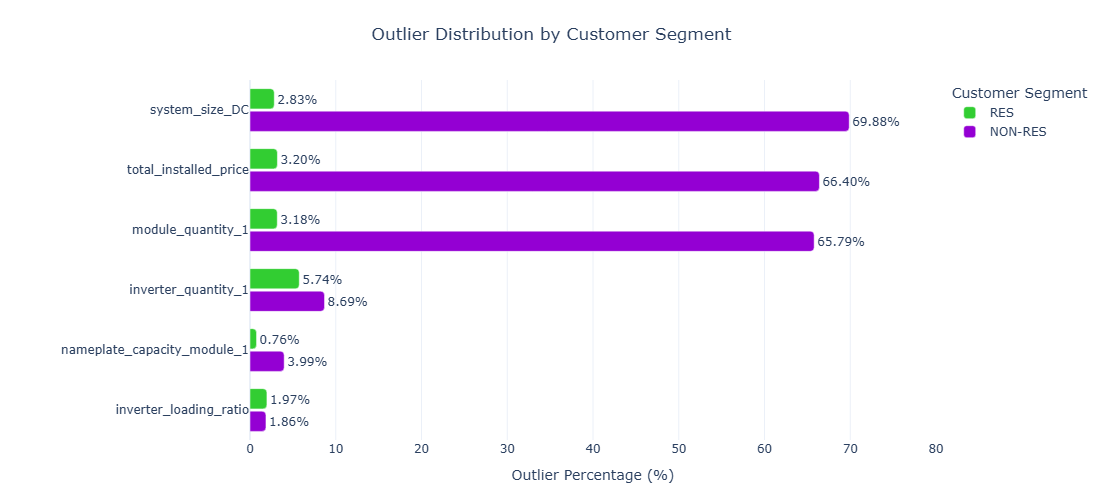

In [40]:
# Prepare data for visualization
outlier_plot_data = outlier_segment_summary.reset_index()

# Create a grouped horizontal bar chart
fig = px.bar(
    outlier_plot_data,
    x="Outliers (%)",
    y="Variable",
    color="Customer Segment",
    orientation="h",
    barmode="group",
    text="Outliers (%)",
    color_discrete_map={
        "RES": "limegreen",
        "NON-RES": "darkviolet"
    },
    category_orders={
        "Customer Segment": ["RES", "NON-RES"]
    },
    title="Outlier Distribution by Customer Segment"
)

# Format percentage labels
fig.update_traces(
    texttemplate="%{x:.2f}%",
    textposition="outside",
    cliponaxis=False,
    hovertemplate="%{y}<br>Outliers: %{x:.2f}%"
)

# Customize chart layout
fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    height=500,
    barcornerradius=4,
    bargap=0.25,
    bargroupgap=0.10,
    xaxis_title="Outlier Percentage (%)",
    yaxis_title=None,
    legend_title="Customer Segment",
    xaxis=dict(range=[0, 80]),
    yaxis=dict(autorange="reversed"),
    margin=dict(l=250, r=80, t=80, b=60)
)

fig.show()

#### Key Findings

- Outlier rates are substantially higher in NON-RES installations for system size (69.88% vs. 2.83%), installation price (66.40% vs. 3.20%), and module quantity (65.79% vs. 3.18%).
- Global IQR thresholds predominantly reflect the majority class distribution.
- Automatic outlier removal could exacerbate class imbalance and eliminate valuable predictive information.

#### Domain-Based Validity Checks

This analysis identifies potentially invalid numerical values using basic physical and logical constraints.   
Unlike statistical outlier detection, these checks focus on values that fall outside meaningful ranges.   
Missing values are excluded from the validity checks.

In [41]:
# Define basic physical and logical validity rules
validity_rules = {
    "system_size_DC": lambda x: x > 0,
    "total_installed_price": lambda x: x >= 0,
    "rebate_or_grant": lambda x: x >= 0,
    "inverter_loading_ratio": lambda x: x > 0,
    "battery_rated_capacity_kW": lambda x: x >= 0,
    "battery_rated_capacity_kWh": lambda x: x >= 0
}

# Define validity rules for component groups
for i in range(1, 4):

    validity_rules.update({
        f"module_quantity_{i}":
            lambda x: (x >= 0) & (x % 1 == 0),

        f"inverter_quantity_{i}":
            lambda x: (x >= 0) & (x % 1 == 0),

        f"azimuth_{i}":
            lambda x: x.between(0, 360),

        f"tilt_{i}":
            lambda x: x.between(0, 90),

        f"nameplate_capacity_module_{i}":
            lambda x: x > 0,

        f"efficiency_module_{i}":
            lambda x: (x > 0) & (x <= 1),

        f"output_capacity_inverter_{i}":
            lambda x: x > 0
    })

# Evaluate each variable against its validity rule
validity_results = []

for col, rule in validity_rules.items():

    values = df[col].dropna()
    invalid_values = values[~rule(values)]

    validity_results.append({
        "Variable": col,
        "Non-Missing Count": len(values),
        "Minimum": values.min(),
        "Maximum": values.max(),
        "Potentially Invalid Count": len(invalid_values),
        "Potentially Invalid (%)": (
            len(invalid_values) / len(values) * 100
            if len(values) > 0 else np.nan
        )
    })

validity_summary = (
    pd.DataFrame(validity_results)
    .set_index("Variable")
    .sort_values("Potentially Invalid Count", ascending=False)
)

display(validity_summary.round(4))

,Non-Missing Count,Minimum,Maximum,Potentially Invalid Count,Potentially Invalid (%)
Variable,,,,,
system_size_DC,988692,0.0055,1.330561e+04,0,0.0
total_installed_price,814364,0.0100,6.150719e+07,0,0.0
rebate_or_grant,954632,0.0000,4.317390e+06,0,0.0
inverter_loading_ratio,753185,0.7500,1.500000e+00,0,0.0
battery_rated_capacity_kW,15449,0.2670,2.442240e+03,0,0.0
battery_rated_capacity_kWh,7012,1.7000,2.000000e+03,0,0.0
module_quantity_1,996328,1.0000,3.165140e+05,0,0.0
inverter_quantity_1,994951,1.0000,5.680000e+03,0,0.0
azimuth_1,684393,0.0000,3.600000e+02,0,0.0


#### Key Findings

- No violations of the defined physical and logical validity constraints were detected among non-missing values across the 27 evaluated variables.
- Statistical outliers should not automatically be interpreted as invalid observations.

### 1.3.6 Data Quality Summary

| Quality Dimension | Key Findings | Recommended Action |
|---|---|---|
| Missing Values | 36 variables with over 90% missingness, including 2 completely missing variables | Evaluate feature relevance and missingness patterns |
| Duplicate Records | No exact duplicates; repeated identifiers and potential duplicate installations | Assess potential data leakage |
| Variable Variability | 1 constant and 13 near-constant variables | Evaluate predictive relevance before removal |
| Data Types | Installation date stored as an object | Apply appropriate feature transformations |
| Statistical Outliers | Substantially higher outlier rates in the NON-RES segment for several features | Avoid automatic outlier removal |
| Domain Validity | No rule violations across 27 evaluated numerical variables | Investigate economically implausible installation prices |

The original dataset remains unchanged, containing 1,000,000 observations and 78 variables.

## 1.4 Exploratory Data Analysis (EDA)

The objective of this exploratory analysis is to identify patterns, relationships, and distinguishing characteristics between residential (RES) and non-residential (NON-RES) solar installations.

The analysis focuses on technical and financial characteristics to identify potentially informative features for customer segment classification.

### 1.4.1 Equipment and System Configuration by Customer Segment

This section examines differences in equipment usage, system configuration, ownership, and installation characteristics between residential (RES) and
non-residential (NON-RES) solar installations.   
The analysis compares feature prevalence across customer segments while accounting for data availability to identify potentially informative characteristics for classification.

In [42]:
# Select features for equipment and system configuration analysis
equipment_features = [
    "tracking",
    "ground_mounted",
    "third_party_owned",
    "self_installed",
    "micro_inverter_1",
    "solar_storage_hybrid_inverter_1",
    "built_in_meter_inverter_1",
    "DC_optimizer"
]

# Validate observed feature values
equipment_validation = pd.DataFrame({
    "Data Type": df[equipment_features].dtypes.astype(str),
    "Unique Values": [
        sorted(df[col].dropna().unique().tolist())
        for col in equipment_features
    ],
    "Binary Valid": [
        df[col].dropna().isin([0, 1]).all()
        for col in equipment_features
    ]
})

equipment_validation.index.name = "Variable"

display(equipment_validation)

,Data Type,Unique Values,Binary Valid
Variable,,,
tracking,float64,"[0.0, 1.0]",True
ground_mounted,float64,"[0.0, 1.0]",True
third_party_owned,float64,"[0.0, 1.0]",True
self_installed,float64,"[0.0, 1.0]",True
micro_inverter_1,float64,"[0.0, 1.0]",True
solar_storage_hybrid_inverter_1,float64,"[0.0, 1.0]",True
built_in_meter_inverter_1,float64,"[0.0, 1.0]",True
DC_optimizer,float64,"[0.0, 1.0]",True


In [43]:
# Calculate feature prevalence by customer segment
equipment_prevalence = (
    df[equipment_features]
    .groupby(binary_segment)
    .mean()
    .mul(100)
    .T
)

# Calculate data coverage by customer segment
equipment_coverage = (
    df[equipment_features]
    .notna()
    .groupby(binary_segment)
    .mean()
    .mul(100)
    .T
)

# Create a summary table
equipment_summary = pd.DataFrame({
    "RES Prevalence (%)": equipment_prevalence["RES"],
    "NON-RES Prevalence (%)": equipment_prevalence["NON-RES"],
    "RES Coverage (%)": equipment_coverage["RES"],
    "NON-RES Coverage (%)": equipment_coverage["NON-RES"],
    "Prevalence Difference (pp)": (
        equipment_prevalence["NON-RES"]
        - equipment_prevalence["RES"]
    )
})

equipment_summary.index.name = "Variable"

display(equipment_summary.round(2))

,RES Prevalence (%),NON-RES Prevalence (%),RES Coverage (%),NON-RES Coverage (%),Prevalence Difference (pp)
Variable,,,,,
tracking,0.50,2.54,90.10,84.10,2.04
ground_mounted,2.17,22.96,76.16,67.82,20.80
third_party_owned,38.42,19.00,91.71,92.65,-19.41
self_installed,2.46,1.90,95.57,94.91,-0.56
micro_inverter_1,32.14,12.83,99.45,98.18,-19.31
solar_storage_hybrid_inverter_1,0.41,0.20,81.81,78.47,-0.21
built_in_meter_inverter_1,49.58,64.35,90.06,89.01,14.77
DC_optimizer,26.71,12.13,99.52,98.69,-14.58


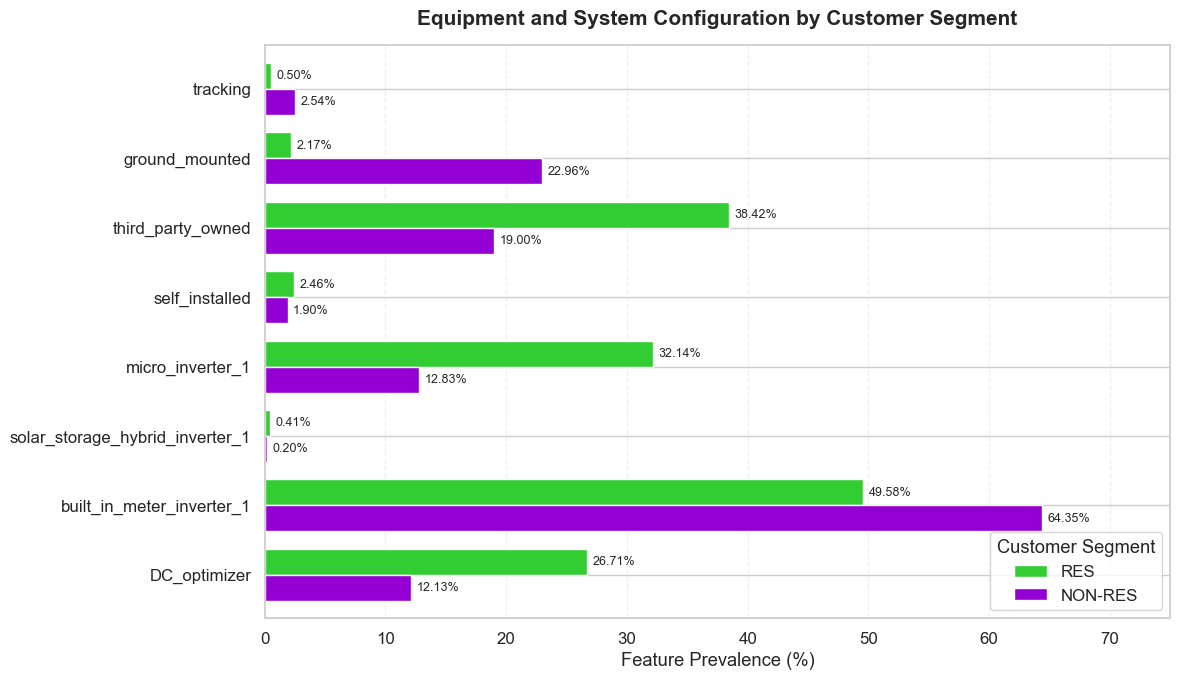

In [44]:
# Visualize feature prevalence by customer segment
ax = equipment_prevalence[["RES", "NON-RES"]].plot(
    kind="barh",
    figsize=(12, 7),
    color=["limegreen", "darkviolet"],
    width=0.75
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=4,
        fontsize=9
    )

# Customize the chart
ax.set_title(
    "Equipment and System Configuration by Customer Segment", 
    fontsize=15,
    pad=15,
    fontweight="bold"
)

ax.set_xlabel("Feature Prevalence (%)")
ax.set_ylabel("")
ax.set_xlim(0, 75)
ax.invert_yaxis()

ax.legend(title="Customer Segment", loc="lower right")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Key Findings**

- NON-RES installations more frequently feature ground-mounted systems and built-in inverter meters.
- RES installations show higher prevalence of third-party ownership, microinverters, and DC optimizers.
- Tracking systems, self-installation, and solar-storage hybrid inverters are relatively uncommon in both segments.

**Domain Interpretation**

- Ground-mounted systems and tracking technologies may be more common in NON-RES installations due to greater space availability and different system design requirements.
- Microinverters and DC optimizers may be particularly suitable for residential rooftops, where shading and varying panel orientations can affect system performance.
- Higher third-party ownership prevalence in RES installations may reflect the use of residential solar leasing and power purchase agreements (PPAs).

### 1.4.2 Installation Cost and Price Distribution Analysis

The objective of this analysis is to compare total installation prices and prices per watt between residential (RES) and non-residential (NON-RES) solar installations, examining their central tendency, variability, distribution shape, and overlap between customer segments.

In [45]:
# Create a separate DataFrame for installation cost analysis
cost_data = df[["total_installed_price", "system_size_DC"]].copy()

# Calculate price per watt for positive system sizes
cost_data["price_per_watt"] = (
    cost_data["total_installed_price"]
    / (cost_data["system_size_DC"].where(
        cost_data["system_size_DC"] > 0
    ) * 1000)
)

# Preview the calculated variable
display(cost_data.head())

Variable,total_installed_price,system_size_DC,price_per_watt
0,14558.0,2.016,7.221230
1,26096.0,3.360,7.766667
2,91139.0,13.440,6.781176
3,40043.0,5.520,7.254167
4,21497.0,2.530,8.496838


In [46]:
# Select installation cost variables
cost_features = ["total_installed_price", "price_per_watt"]

# Calculate available observations by customer segment
cost_counts = (
    cost_data[cost_features]
    .groupby(binary_segment)
    .count()
    .T
)

# Calculate data coverage by customer segment
cost_coverage = (
    cost_data[cost_features]
    .notna()
    .groupby(binary_segment)
    .mean()
    .mul(100)
    .T
)

# Combine results into a summary table
cost_data_summary = pd.DataFrame({
    "RES Count": cost_counts["RES"],
    "NON-RES Count": cost_counts["NON-RES"],
    "RES Coverage (%)": cost_coverage["RES"],
    "NON-RES Coverage (%)": cost_coverage["NON-RES"]
})

cost_data_summary.index.name = "Variable"

display(cost_data_summary.round(2))

,RES Count,NON-RES Count,RES Coverage (%),NON-RES Coverage (%)
Variable,,,,
total_installed_price,794686,19678,81.56,76.60
price_per_watt,794647,19675,81.56,76.59


**Data Coverage**

- Data coverage is approximately 5 percentage points higher in RES (81.56%) than in NON-RES (76.60%) installations.

In [47]:
# Calculate descriptive statistics by customer segment
cost_statistics = (
    cost_data[cost_features]
    .groupby(binary_segment)
    .agg(["mean", "median", "std"])
    .T
)

# Rename statistical measures
cost_statistics = cost_statistics.rename(
    index={
        "mean": "Mean",
        "median": "Median",
        "std": "Standard Deviation"
    },
    level=1
)

# Set index and column order
cost_statistics.index.names = ["Variable", "Statistic"]
cost_statistics = cost_statistics[["RES", "NON-RES"]]

display(
    cost_statistics.style
    .format("{:,.2f}")
    .set_caption("Descriptive Statistics of Installation Costs by Customer Segment")
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "15px")
            ]
        }
    ])
)

In [48]:
# Check non-positive price values by customer segment
non_positive_prices = (
    cost_data[cost_features]
    .le(0)
    .groupby(binary_segment)
    .sum()
    .T
)

non_positive_prices.index.name = "Variable"

print("Non-Positive Price Values by Customer Segment")
display(non_positive_prices[["RES", "NON-RES"]])

Non-Positive Price Values by Customer Segment


customer_segment,RES,NON-RES
Variable,,
total_installed_price,0,0
price_per_watt,0,0


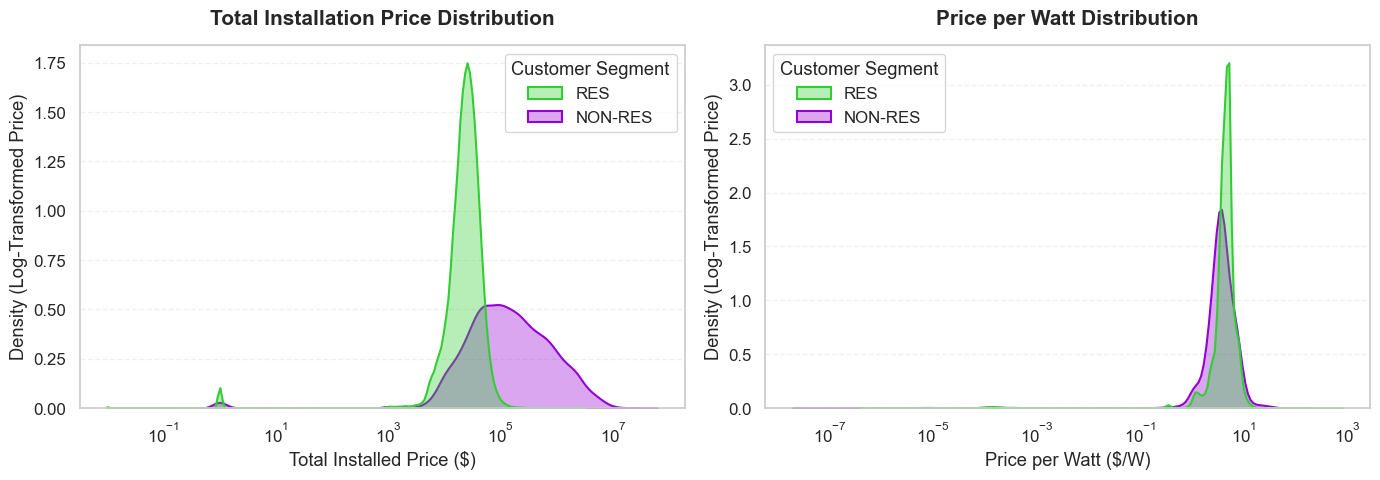

In [49]:
# Prepare data for KDE visualization
cost_plot_data = cost_data[cost_features].copy()
cost_plot_data["Customer Segment"] = binary_segment

# Define customer segment colors
colors = {
    "RES": "limegreen",
    "NON-RES": "darkviolet"
}

# Define visualization settings
metrics = [
    ("total_installed_price", "Total Installation Price Distribution", "Total Installed Price ($)"),
    ("price_per_watt", "Price per Watt Distribution", "Price per Watt ($/W)")
]

# Create KDE plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (variable, title, xlabel) in zip(axes, metrics):

    sns.kdeplot(
        data=cost_plot_data,
        x=variable,
        hue="Customer Segment",
        hue_order=["RES", "NON-RES"],
        palette=colors,
        fill=True,
        alpha=0.35,
        linewidth=1.5,
        common_norm=False,
        log_scale=True,
        cut=0,
        ax=ax
    )

    # Customize the chart
    ax.set_title(
        title,
        fontsize=15,
        pad=15,
        fontweight="bold"
    )

    ax.set_xlabel(xlabel)
    ax.set_ylabel("Density (Log-Transformed Price)")

    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

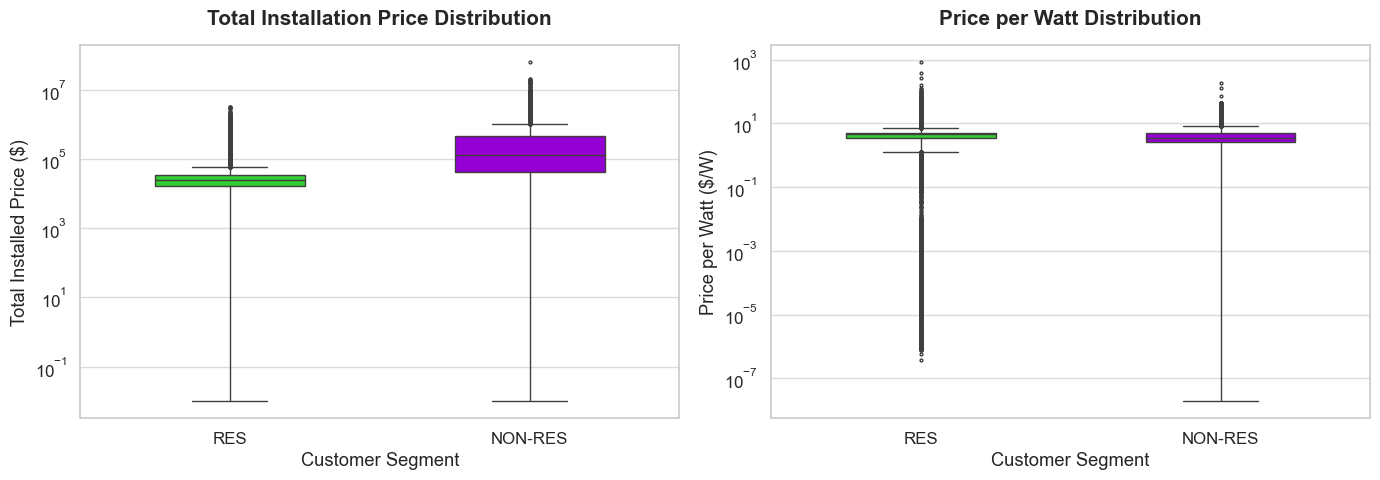

In [50]:
# Create box plots for installation price distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (variable, title, ylabel) in zip(axes, metrics):

    sns.boxplot(
        data=cost_plot_data,
        x="Customer Segment",
        y=variable,
        hue="Customer Segment",
        order=["RES", "NON-RES"],
        palette=colors,
        legend=False,
        width=0.5,
        showfliers=True,
        fliersize=2,
        saturation=1,
        ax=ax
    )

    ax.set_yscale("log")

    # Customize the chart
    ax.set_title(
        title,
        fontsize=15,
        pad=15,
        fontweight="bold"
    )

    ax.set_xlabel("Customer Segment")
    ax.set_ylabel(ylabel)

    ax.grid(axis="y", linestyle="-", color="lightgray", linewidth=1, alpha=0.8)
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Key Findings

- NON-RES installations have substantially higher total installation prices but lower prices per watt.
- Total installation prices exhibit right-skewed distributions and greater variability in the NON-RES segment.
- Price per watt distributions show substantial overlap between customer segments.
- Total installation price appears to offer better segment separation than price per watt.
- Extremely low and high price values require further investigation during Data Preparation.

### 1.4.3 New Construction and Customer Segment

The objective of this analysis is to examine the relationship between new construction and customer segment.

In [51]:
# Check data type and unique values
print("Data Type:", df["new_construction"].dtype)
print("Unique Values:", df["new_construction"].dropna().unique())

# Calculate data availability by customer segment
construction_summary = (
    df["new_construction"]
    .groupby(binary_segment)
    .agg(
        Count="count",
        Coverage=lambda x: x.notna().mean() * 100
    )
    .rename(columns={"Coverage": "Coverage (%)"})
)

construction_summary.index.name = "Customer Segment"

print("\nNew Construction Data Coverage by Customer Segment")
display(construction_summary.loc[["RES", "NON-RES"]].round(2))

Data Type: float64
Unique Values: [1. 0.]

New Construction Data Coverage by Customer Segment


,Count,Coverage (%)
Customer Segment,,
RES,206755,21.22
NON-RES,289,1.12


In [52]:
# Calculate construction type counts by customer segment
construction_counts = pd.crosstab(
    binary_segment,
    df["new_construction"]
)

# Calculate percentages within each customer segment
construction_percentages = (
    construction_counts.div(
        construction_counts.sum(axis=1), axis=0
    ) * 100
)

# Rename columns and reorder customer segments
construction_percentages = construction_percentages.rename(
    columns={0: "Existing Construction", 1: "New Construction"}
).loc[["RES", "NON-RES"]]

construction_percentages.index.name = "Customer Segment"
construction_percentages.columns.name = None

print("Construction Type Distribution by Customer Segment (%)")
display(construction_percentages.round(2))

Construction Type Distribution by Customer Segment (%)


,Existing Construction,New Construction
Customer Segment,,
RES,72.57,27.43
NON-RES,100.00,0.00


**Key Findings**

- New construction accounts for 27.43% of RES installations with available data.
- No new construction installations are recorded among the 289 NON-RES observations with available data.
- Low and unequal data coverage (21.22% for RES and 1.12% for NON-RES) limits the reliability of this comparison.
- Segment-specific missingness may carry predictive information but requires careful evaluation for potential target leakage.

### 1.4.4 System Size and Customer Segment

The objective of this analysis is to examine differences in system size between residential (RES) and non-residential (NON-RES) installations, assess the overlap of their distributions, and evaluate the potential relevance of system size for customer segment classification.

In [53]:
# Calculate system size statistics by customer segment
size_statistics = (
    df["system_size_DC"]
    .groupby(binary_segment)
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std="std",
        Minimum="min",
        Maximum="max",
        Coverage=lambda x: x.notna().mean() * 100
    )
    .loc[["RES", "NON-RES"]]
    .T
)

size_statistics = size_statistics.rename(
    index={
        "Std": "Standard Deviation",
        "Coverage": "Coverage (%)"
    }
)

size_statistics.index.name = "Statistic"

print("Descriptive Statistics of System Size (kW DC) by Customer Segment")
display(size_statistics.round(2))

Descriptive Statistics of System Size (kW DC) by Customer Segment


customer_segment,RES,NON-RES
Statistic,,
Count,963516.00,25176.00
Mean,6.16,130.34
Median,5.49,32.64
Standard Deviation,5.69,265.95
Minimum,0.01,0.03
Maximum,1106.56,13305.61
Coverage (%),98.89,98.00


In [54]:
# Check non-positive system size values
non_positive_size = (
    df["system_size_DC"]
    .le(0)
    .groupby(binary_segment)
    .sum()
)

print("Non-Positive System Size Values")
display(non_positive_size.loc[["RES", "NON-RES"]])

Non-Positive System Size Values


customer_segment
RES        0
NON-RES    0
Name: system_size_DC, dtype: int64

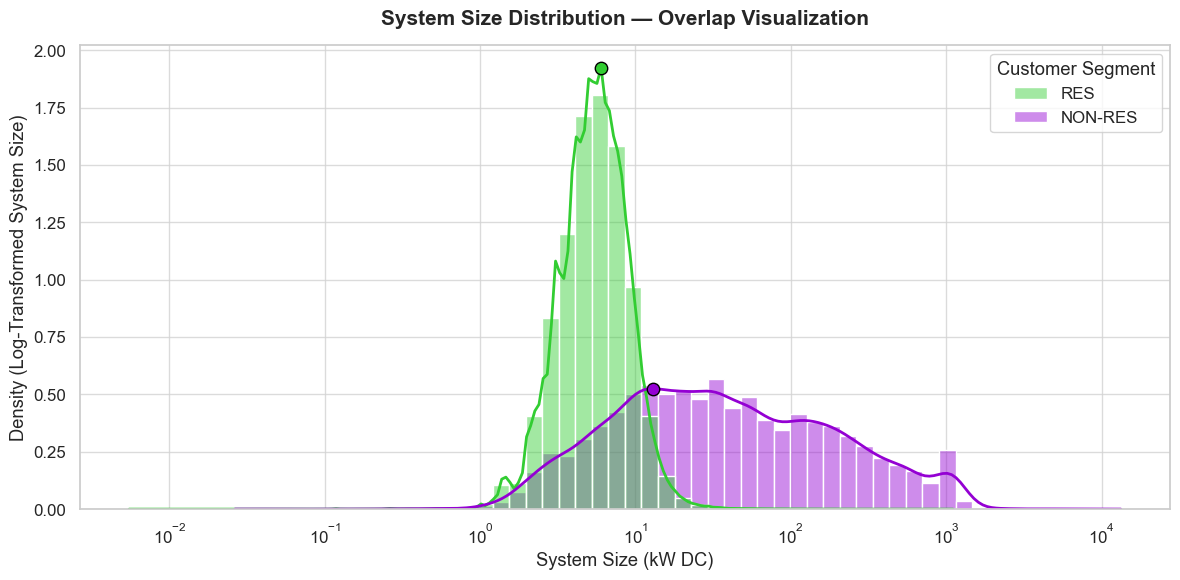

In [55]:
# Prepare system size data for visualization
size_plot_data = df[["system_size_DC"]].copy()
size_plot_data["Customer Segment"] = binary_segment

# Define customer segment colors
colors = {
    "RES": "limegreen",
    "NON-RES": "darkviolet"
}

fig, ax = plt.subplots(figsize=(12, 6))

# Plot normalized histograms
sns.histplot(
    data=size_plot_data,
    x="system_size_DC",
    hue="Customer Segment",
    hue_order=["RES", "NON-RES"],
    palette=colors,
    stat="density",
    common_norm=False,
    common_bins=True,
    bins=60,
    log_scale=True,
    alpha=0.45,
    ax=ax
)

# Add KDE curves and mark density peaks
for segment in ["RES", "NON-RES"]:

    sns.kdeplot(
        data=size_plot_data.loc[
            size_plot_data["Customer Segment"] == segment
        ],
        x="system_size_DC",
        color=colors[segment],
        log_scale=True,
        linewidth=2,
        cut=0,
        ax=ax
    )

    # Identify the peak of the KDE curve
    x_values, y_values = ax.lines[-1].get_data()
    peak_index = np.argmax(y_values)

    ax.scatter(
        x_values[peak_index],
        y_values[peak_index],
        color=colors[segment],
        edgecolor="black",
        s=80,
        zorder=5
    )

# Customize the chart
ax.set_title(
    "System Size Distribution — Overlap Visualization",
    fontsize=15,
    pad=15,
    fontweight="bold"
)

ax.set_xlabel("System Size (kW DC)")
ax.set_ylabel("Density (Log-Transformed System Size)")

ax.grid(
    axis="both",
    linestyle="-",
    color="lightgray",
    linewidth=1,
    alpha=0.8
)

ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Key Findings

- The median system size of NON-RES installations is approximately six times larger than that of RES installations (32.64 vs. 5.49 kW DC).
- NON-RES installations exhibit a broader system size distribution and substantially greater variability.
- Data coverage is high in both segments (98.89% for RES and 98.00% for NON-RES).
- Despite distribution overlap, system size appears to be an informative feature for customer segment classification.

### 1.4.5 Relationship Between System Size and Installation Cost

The objective of this analysis is to examine the relationship between system size and total installation cost and determine whether this relationship differs between RES and NON-RES installations.

In [56]:
# Prepare data for correlation analysis
size_cost_data = df[
    ["system_size_DC", "total_installed_price"]
].copy()

size_cost_data["Customer Segment"] = binary_segment

# Calculate correlation coefficients by customer segment
correlation_results = []

for segment in ["RES", "NON-RES"]:

    segment_data = (
        size_cost_data.loc[
            size_cost_data["Customer Segment"] == segment,
            ["system_size_DC", "total_installed_price"]
        ]
        .dropna()
    )

    correlation_results.append({
        "Customer Segment": segment,
        "Valid Observations": len(segment_data),
        "Pearson": segment_data["system_size_DC"].corr(
            segment_data["total_installed_price"], method="pearson"
        ),
        "Spearman": segment_data["system_size_DC"].corr(
            segment_data["total_installed_price"], method="spearman"
        )
    })

correlation_summary = (
    pd.DataFrame(correlation_results)
    .set_index("Customer Segment")
)

print("Correlation Between System Size and Total Installed Price")
display(correlation_summary.round(3))

Correlation Between System Size and Total Installed Price


,Valid Observations,Pearson,Spearman
Customer Segment,,,
RES,794647,0.746,0.702
NON-RES,19675,0.685,0.894


In [57]:
# Prepare valid paired observations
plot_data = df[["system_size_DC", "total_installed_price"]].copy()
plot_data["Customer Segment"] = binary_segment
plot_data = plot_data.dropna()

# Examine system size percentiles by customer segment
size_percentiles = (
    plot_data.groupby("Customer Segment")["system_size_DC"]
    .quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .unstack(level=0)
    [["RES", "NON-RES"]]
)

size_percentiles.index = [
    "1%", "5%", "25%", "50%",
    "75%", "90%", "95%", "99%"
]

size_percentiles.index.name = "Percentile"

print("System Size Percentiles by Customer Segment (kW DC)")
display(size_percentiles.round(2))

System Size Percentiles by Customer Segment (kW DC)


Customer Segment,RES,NON-RES
Percentile,,
1%,1.47,1.82
5%,2.30,3.15
25%,3.92,11.86
50%,5.50,36.60
75%,7.60,139.12
90%,10.01,381.11
95%,11.88,660.82
99%,17.52,1124.88


In [58]:
# Evaluate coverage within the selected system size range
common_range_data = plot_data[
    plot_data["system_size_DC"].between(1, 18)
].copy()

range_summary = pd.DataFrame({
    "Total Observations": plot_data.groupby("Customer Segment").size(),
    "Observations in Range": common_range_data.groupby("Customer Segment").size()
})

range_summary["Coverage (%)"] = (
    range_summary["Observations in Range"] /
    range_summary["Total Observations"] * 100
)

display(range_summary.loc[["RES", "NON-RES"]].round(2))

,Total Observations,Observations in Range,Coverage (%)
Customer Segment,,,
RES,794647,787080,99.05
NON-RES,19675,6679,33.95


**System Size Range Selection**

The 1–18 kW DC range was selected to compare installations of similar capacity. It covers 99.05% of RES and 33.95% of NON-RES observations with valid paired data.

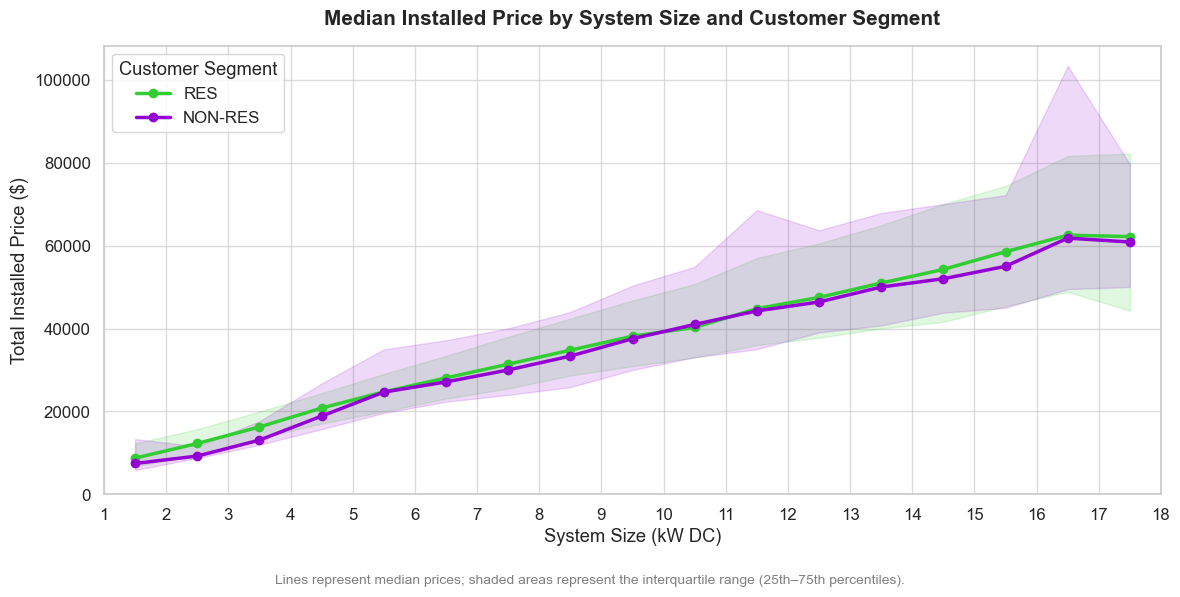

In [59]:
# Create system size intervals
binned_data = common_range_data.copy()

binned_data["Size Bin"] = pd.cut(
    binned_data["system_size_DC"],
    bins=np.arange(1, 19, 1),
    include_lowest=True
)

# Calculate price statistics within each interval
binned_statistics = (
    binned_data
    .groupby(["Customer Segment", "Size Bin"], observed=True)
    ["total_installed_price"]
    .agg(
        Count="count",
        Median="median",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

# Calculate interval midpoints
binned_statistics["System Size"] = (
    binned_statistics["Size Bin"]
    .apply(lambda x: x.mid)
    .astype(float)
)

# Plot median prices and interquartile ranges
fig, ax = plt.subplots(figsize=(12, 6))

for segment in ["RES", "NON-RES"]:

    segment_data = binned_statistics[
        binned_statistics["Customer Segment"] == segment
    ].sort_values("System Size")

    ax.plot(
        segment_data["System Size"],
        segment_data["Median"],
        color=colors[segment],
        marker="o",
        linewidth=2.5,
        label=segment
    )

    ax.fill_between(
        segment_data["System Size"],
        segment_data["Q1"],
        segment_data["Q3"],
        color=colors[segment],
        alpha=0.15
    )

# Customize the chart
ax.set_title(
    "Median Installed Price by System Size and Customer Segment",
    fontsize=15,
    pad=15,
    fontweight="bold"
)

ax.set_xlabel("System Size (kW DC)")
ax.set_ylabel("Total Installed Price ($)")
ax.set_xticks(np.arange(1, 19, 1))
ax.set_xlim(1, 18)
ax.set_ylim(bottom=0)

ax.grid(
    axis="both",
    linestyle="-",
    color="lightgray",
    linewidth=1,
    alpha=0.8
)

ax.set_axisbelow(True)
ax.legend(title="Customer Segment", loc="upper left")

fig.text(
    0.5, 0.01,
    "Lines represent median prices; shaded areas represent "
    "the interquartile range (25th–75th percentiles).",
    ha="center",
    fontsize=10,
    color="gray"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

#### Key Findings

- Both segments exhibit a strong positive relationship between system size and total installed price.
- RES installations exhibit a stronger linear relationship (Pearson: 0.746 vs. 0.685), while NON-RES installations exhibit a stronger monotonic relationship (Spearman: 0.894 vs. 0.702).
- Within the 1–18 kW DC range, median installation prices are similar, with substantial overlap in their interquartile ranges.
- Differences in system size may partly explain the overall installation price gap between customer segments.
- Total installed price may provide limited additional discriminatory information when comparing installations of similar capacity.

### 1.4.6 Feature Associations and Correlation Analysis

The objective of this analysis is to examine relationships between features, identify potential redundancy, and assess their associations with the target variable.

In [60]:
# Define numerical features
numerical_features = [
    "system_size_DC",
    "total_installed_price",
    "rebate_or_grant",
    "azimuth_1",
    "tilt_1",
    "module_quantity_1",
    "nameplate_capacity_module_1",
    "efficiency_module_1",
    "inverter_quantity_1",
    "output_capacity_inverter_1",
    "inverter_loading_ratio"
]

# Define binary and categorical features
categorical_features = [
    "expansion_system",
    "multiple_phase_system",
    "new_construction",
    "tracking",
    "ground_mounted",
    "state",
    "utility_service_territory",
    "third_party_owned",
    "self_installed",
    "additional_modules",
    "technology_module_1",
    "BIPV_module_1",
    "bifacial_module_1",
    "additional_inverters",
    "micro_inverter_1",
    "solar_storage_hybrid_inverter_1",
    "built_in_meter_inverter_1",
    "DC_optimizer"
]

In [61]:
from scipy.stats import pointbiserialr

# Prepare numerical features for association analysis
association_data = df[numerical_features + categorical_features].copy()
association_data["price_per_watt"] = cost_data["price_per_watt"]

# Encode the binary target variable
target_binary = binary_segment.map({"RES": 0, "NON-RES": 1})

# Calculate point-biserial correlations
numerical_associations = []

for feature in numerical_features + ["price_per_watt"]:

    valid = association_data[feature].notna() & target_binary.notna()

    correlation, _ = pointbiserialr(
        target_binary[valid],
        association_data.loc[valid, feature]
    )

    numerical_associations.append({
        "Feature": feature,
        "Correlation": correlation,
        "Absolute Correlation": abs(correlation),
        "RES Coverage (%)": valid[binary_segment == "RES"].mean() * 100,
        "NON-RES Coverage (%)": valid[binary_segment == "NON-RES"].mean() * 100
    })

numerical_associations = (
    pd.DataFrame(numerical_associations)
    .set_index("Feature")
    .sort_values("Absolute Correlation", ascending=False)
)

print("Numerical Feature–Target Associations")
display(numerical_associations.round(3))

Numerical Feature–Target Associations


,Correlation,Absolute Correlation,RES Coverage (%),NON-RES Coverage (%)
Feature,,,,
system_size_DC,0.416,0.416,98.892,98.003
total_installed_price,0.371,0.371,81.564,76.601
output_capacity_inverter_1,0.336,0.336,83.337,68.220
module_quantity_1,0.176,0.176,99.664,98.455
tilt_1,-0.150,0.150,68.566,71.019
rebate_or_grant,0.092,0.092,95.661,87.968
inverter_quantity_1,0.055,0.055,99.518,98.618
efficiency_module_1,-0.052,0.052,90.716,85.029
nameplate_capacity_module_1,0.040,0.040,90.762,85.266


In [62]:
from scipy.stats import chi2_contingency

# Calculate bias-corrected Cramér's V
def cramers_v(x, y):
    contingency = pd.crosstab(x, y)
    n = contingency.to_numpy().sum()
    r, k = contingency.shape

    if n <= 1 or r < 2 or k < 2:
        return np.nan

    chi2 = chi2_contingency(contingency, correction=False)[0]
    phi2 = chi2 / n

    phi2_corrected = max(
        0, phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corrected = r - (r - 1)**2 / (n - 1)
    k_corrected = k - (k - 1)**2 / (n - 1)

    denominator = min(k_corrected - 1, r_corrected - 1)

    return np.sqrt(phi2_corrected / denominator) if denominator > 0 else np.nan


# Calculate categorical feature–target associations
categorical_associations = []

for feature in categorical_features:

    valid = association_data[feature].notna() & target_binary.notna()

    association = cramers_v(
        association_data.loc[valid, feature],
        target_binary[valid]
    )

    categorical_associations.append({
        "Feature": feature,
        "Cramér's V": association,
        "RES Coverage (%)": valid[binary_segment == "RES"].mean() * 100,
        "NON-RES Coverage (%)": valid[binary_segment == "NON-RES"].mean() * 100
    })

categorical_associations = (
    pd.DataFrame(categorical_associations)
    .set_index("Feature")
    .sort_values("Cramér's V", ascending=False)
)

print("Categorical Feature–Target Associations")
display(categorical_associations.round(3))

Categorical Feature–Target Associations


,Cramér's V,RES Coverage (%),NON-RES Coverage (%)
Feature,,,
ground_mounted,0.194,76.160,67.823
multiple_phase_system,0.116,100.000,100.000
additional_inverters,0.068,99.902,99.692
micro_inverter_1,0.065,99.453,98.182
third_party_owned,0.064,91.714,92.647
technology_module_1,0.057,94.455,91.533
DC_optimizer,0.052,99.523,98.688
built_in_meter_inverter_1,0.046,90.057,89.015
tracking,0.042,90.098,84.102


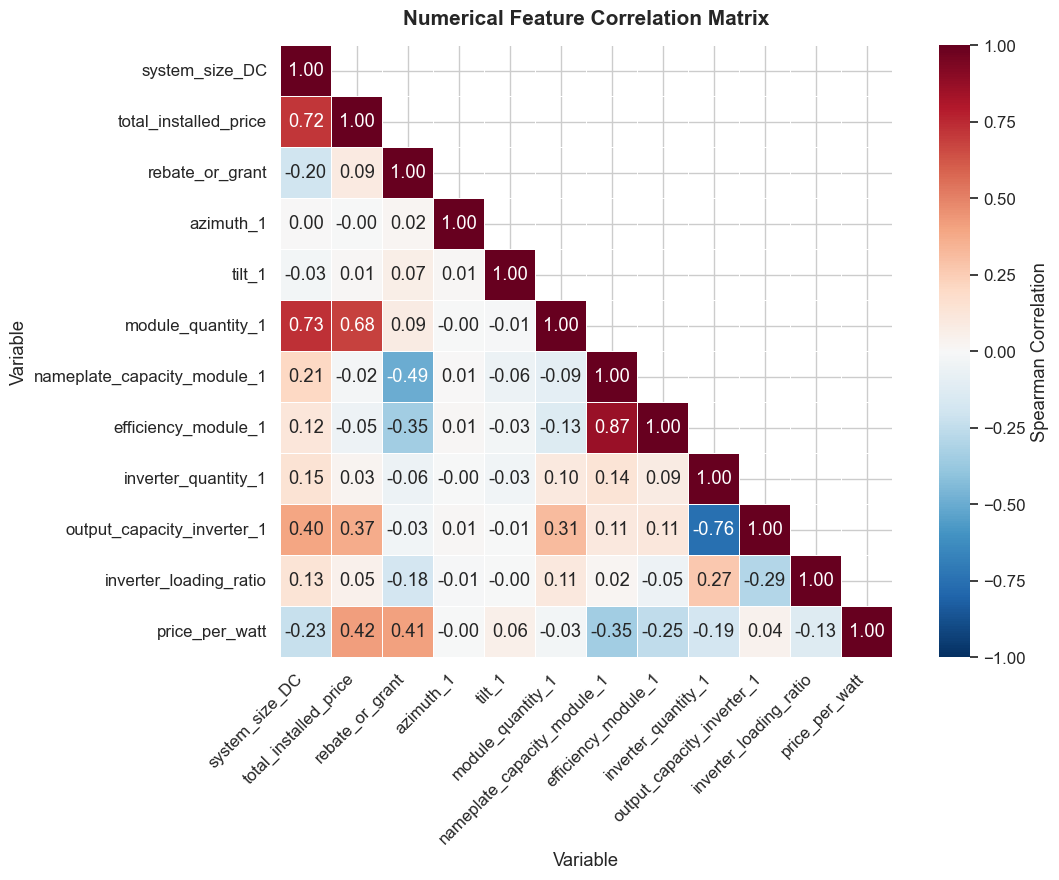

In [63]:
# Calculate Spearman correlations between numerical features
correlation_matrix = association_data[
    numerical_features + ["price_per_watt"]
].corr(method="spearman")

# Mask the upper triangle
mask = np.triu(
    np.ones_like(correlation_matrix, dtype=bool),
    k=1
)

# Visualize the correlation matrix
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Spearman Correlation"}
)

plt.title(
    "Numerical Feature Correlation Matrix",
    fontsize=15,
    pad=15,
    fontweight="bold"
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

#### Key Findings

- System size (0.416), total installed price (0.371), and inverter output capacity (0.336) exhibit the strongest numerical associations with the target.
- Ground-mounted systems (0.194) and multiple-phase systems (0.116) exhibit the strongest associations among the evaluated categorical features.
- Module nameplate capacity and module efficiency exhibit a strong positive correlation (0.87).
- Inverter quantity and inverter output capacity exhibit a strong negative correlation (-0.76).
- System size is strongly correlated with module quantity (0.73) and total installed price (0.72).
- Strongly correlated features should be evaluated for potential redundancy during Feature Selection.

### 1.4.7 EDA Summary

- System size, total installed price, and inverter output capacity exhibit the strongest numerical associations with the target.
- Ground-mounted installations and multiple-phase systems exhibit the strongest categorical associations among the evaluated features.
- RES and NON-RES installations differ in equipment configuration, ownership, system size, and installation cost.
- Installations of comparable capacity within the 1–18 kW DC range exhibit similar median prices.
- Strong correlations between several numerical features indicate potential feature redundancy.
- Segment-specific missingness, extreme values, and severe class imbalance require careful consideration during data preparation and modeling.

## 2. Data Preparation

Based on the findings from the exploratory data analysis, the dataset is prepared for customer segment classification through targeted feature removal, data cleaning, feature engineering, and preprocessing while minimizing the risk of data leakage.

### 2.1 Target Variable Preparation

The original customer segments are consolidated into two classes: residential (RES) and non-residential (NON-RES). A working copy of the dataset is created to preserve the original data.

In [64]:
# Create a working copy of the original dataset
df_prepared = df.copy()

# Assign the binary customer segment
df_prepared["customer_segment"] = binary_segment

# Display the target distribution
display(df_prepared["customer_segment"].value_counts())

customer_segment
RES        974311
NON-RES     25689
Name: count, dtype: int64

### 2.2 Feature Removal

Based on the data quality assessment and EDA findings, features are reviewed for relevance, missingness, redundancy, and potential data leakage.

**Feature Removal Criteria**

- System identifiers and data provider fields.
- Features with more than 95% missing values.
- Features with potential target leakage, if identified.

Highly correlated features are retained for subsequent feature selection.

In [65]:
# Identify features with excessive missingness
high_missing_features = df_prepared.columns[
    df_prepared.isna().mean() > 0.95
].tolist()

# Define features to remove
features_to_remove = [
    "system_ID_1",
    "system_ID_2",
    "data_provider_1",
    "data_provider_2"
] + high_missing_features

# Remove selected features
df_prepared = df_prepared.drop(columns=features_to_remove)

# Display removal summary
print(f"Removed features: {len(features_to_remove)}")
print(f"Remaining features (excluding target): {df_prepared.shape[1] - 1}")
print(f"Dataset shape: {df_prepared.shape}")

display(pd.DataFrame({"Removed Features": features_to_remove}))

Removed features: 40
Remaining features (excluding target): 37
Dataset shape: (1000000, 38)


,Removed Features
0,system_ID_1
1,system_ID_2
2,data_provider_1
3,data_provider_2
4,azimuth_2
5,azimuth_3
6,tilt_2
7,tilt_3
8,module_manufacturer_2
9,module_model_2


#### Feature Removal Summary

- 40 features were removed: 4 system identifier and data provider fields and 36 features with more than 95% missing values.
- The resulting dataset contains 1,000,000 observations and 37 predictor features.
- No observations were removed.

The missingness threshold was applied to the full dataset before the train-test split, which represents a methodological limitation.

### 2.3 Data Cleaning

Based on the data quality assessment and EDA findings, invalid and anomalous values are addressed while preserving valid observations and meaningful differences between customer segments.

In [66]:
# Examine unusually low installation prices
price_thresholds = [1, 10, 100, 500, 1000]

low_price_summary = pd.DataFrame({
    f"Price ≤ ${threshold:,}": (
        df_prepared["total_installed_price"]
        .le(threshold)
        .groupby(df_prepared["customer_segment"])
        .sum()
    )
    for threshold in price_thresholds
}).T

display(low_price_summary[["RES", "NON-RES"]])

customer_segment,RES,NON-RES
Price ≤ $1,8247,183
Price ≤ $10,8555,197
Price ≤ $100,8932,204
Price ≤ $500,8985,211
"Price ≤ $1,000",9765,250


#### Invalid Installation Prices

An analyst-defined threshold of $1 is used to identify implausibly low installation prices. Values at or below this threshold are replaced with NaN.   
All observations are retained, and missing values will be addressed during data preprocessing.

In [67]:
# Replace implausibly low installation prices with NaN
invalid_price_mask = df_prepared["total_installed_price"] <= 1

df_prepared.loc[
    invalid_price_mask, "total_installed_price"
] = np.nan

print(f"Replaced values: {invalid_price_mask.sum():,}")

Replaced values: 8,430


### 2.4 Feature Engineering

Two normalized economic features are created to account for differences in system capacity:

- `price_per_watt` — total installed price per watt (USD/W).
- `rebate_per_watt` — rebate or grant amount per watt (USD/W).

The installation date is excluded from the predictor set.

In [68]:
# Convert system capacity from kW to W
system_size_watts = df_prepared["system_size_DC"].where(
    df_prepared["system_size_DC"] > 0
) * 1000

# Create normalized economic features
df_prepared["price_per_watt"] = (
    df_prepared["total_installed_price"] / system_size_watts
)

df_prepared["rebate_per_watt"] = (
    df_prepared["rebate_or_grant"] / system_size_watts
)

# Remove installation date
df_prepared = df_prepared.drop(columns=["installation_date"])

# Display descriptive statistics for engineered features
display(
    df_prepared[["price_per_watt", "rebate_per_watt"]]
    .describe().round(2)
)

print(f"Dataset shape: {df_prepared.shape}")

Variable,price_per_watt,rebate_per_watt
count,805892.00,953189.00
mean,4.62,0.22
std,2.36,0.62
min,0.00,0.00
25%,3.60,0.00
50%,4.50,0.00
75%,5.12,0.00
max,823.84,29.53


Dataset shape: (1000000, 39)


#### Feature Engineering Summary

- Extreme values in `price_per_watt` remain after data cleaning.
- The resulting dataset contains 1,000,000 observations and 38 predictor features.

### 2.5 Train–Test Split

The dataset is divided into training and test sets using stratified sampling to preserve the original class distribution. The test set is reserved for final model evaluation.

In [69]:
from sklearn.model_selection import train_test_split

# Separate predictor features and target variable
X = df_prepared.drop(columns=["customer_segment"])
y = df_prepared["customer_segment"]

# Perform stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y,
    shuffle=True
)

# Display dataset dimensions
print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test.shape}")

# Compare class distributions
class_distribution = pd.DataFrame({
    "Original Dataset (%)": y.value_counts(normalize=True) * 100,
    "Training Set (%)": y_train.value_counts(normalize=True) * 100,
    "Test Set (%)": y_test.value_counts(normalize=True) * 100
})

display(class_distribution.round(3))

Training set: (800000, 38)
Test set: (200000, 38)


,Original Dataset (%),Training Set (%),Test Set (%)
customer_segment,,,
RES,97.431,97.431,97.431
NON-RES,2.569,2.569,2.569


#### Train–Test Split Summary

- The training and test sets contain 800,000 and 200,000 observations, respectively.
- The original class distribution (97.431% RES and 2.569% NON-RES) is preserved in both sets to three decimal places.

### 2.6 Data Preprocessing

Predictor features are preprocessed to handle missing values, encode categorical variables, and scale numerical features. All preprocessing transformations are fitted exclusively on training data to prevent data leakage.

**Feature Type Identification**

Predictor features are classified into numerical, binary, and categorical groups to apply appropriate preprocessing transformations.

In [70]:
# Identify binary features
binary_features = [
    col for col in X_train.select_dtypes(include="number").columns
    if set(X_train[col].dropna().unique()).issubset({0, 1})
]

# Identify numerical features
numerical_features = [
    col for col in X_train.select_dtypes(include="number").columns
    if col not in binary_features
]

# Identify categorical features
categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Display feature groups
for group, features in {
    "Numerical": numerical_features,
    "Binary": binary_features,
    "Categorical": categorical_features
}.items():
    print(f"\n{group} features ({len(features)}):")
    print(", ".join(features))


Numerical features (13):
system_size_DC, total_installed_price, rebate_or_grant, azimuth_1, tilt_1, module_quantity_1, nameplate_capacity_module_1, efficiency_module_1, inverter_quantity_1, output_capacity_inverter_1, inverter_loading_ratio, price_per_watt, rebate_per_watt

Binary features (15):
expansion_system, multiple_phase_system, new_construction, tracking, ground_mounted, third_party_owned, self_installed, additional_modules, BIPV_module_1, bifacial_module_1, additional_inverters, micro_inverter_1, solar_storage_hybrid_inverter_1, built_in_meter_inverter_1, DC_optimizer

Categorical features (10):
zip_code, city, state, utility_service_territory, installer_name, module_manufacturer_1, module_model_1, technology_module_1, inverter_manufacturer_1, inverter_model_1


**Preprocessing Strategy**

| Feature Type | Missing Value Imputation | Transformation |
|---|---|---|
| Numerical | Median | RobustScaler |
| Binary | Constant (-1) | No scaling |
| Categorical | Unknown | One-Hot Encoding (max. 50 categories) |

This strategy accounts for extreme numerical values, preserves missingness information in binary features, and limits the dimensionality of high-cardinality categorical features.

**Preprocessing Pipeline**

A ColumnTransformer combines feature-specific preprocessing pipelines to ensure consistent transformations and prevent data leakage during model training and cross-validation.

In [71]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

# Binary preprocessing
binary_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value=-1
    ))
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        max_categories=50,
        handle_unknown="infrequent_if_exist",
        sparse_output=True
    ))
])

# Combine preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline, numerical_features),
        ("binary", binary_pipeline, binary_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    sparse_threshold=1.0
)

display(preprocessor)

,transformers,"[('numerical', ...), ('binary', ...), ...]"
,remainder,'drop'
,sparse_threshold,1.0
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


**Data Preprocessing Summary**

- All 38 predictors were classified into 13 numerical, 15 binary, and 10 categorical features.
- Feature-specific imputation, scaling, and encoding strategies were defined.
- All preprocessing transformations were integrated into a single ColumnTransformer.
- Preprocessing will be fitted within the model training pipeline to prevent data leakage during cross-validation.

### 2.7 Feature Selection

Feature selection aims to reduce redundancy and identify informative predictors while maintaining classification performance.

**Correlation-Based Feature Selection**

Spearman correlation is calculated on the training set to identify potentially redundant numerical features. Feature pairs with an absolute correlation coefficient of at least 0.8 are reviewed.

In [72]:
# Calculate Spearman correlations on training data
correlation_matrix = X_train[numerical_features].corr(
    method="spearman"
)

# Extract unique feature pairs
upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape, dtype=bool),
        k=1
    )
)

# Identify strongly correlated feature pairs
strong_correlations = (
    upper_triangle
    .rename_axis(index="Feature 1", columns="Feature 2")
    .stack()
    .reset_index(name="Spearman Correlation")
)

strong_correlations = strong_correlations[
    strong_correlations["Spearman Correlation"].abs() >= 0.8
].sort_values(
    "Spearman Correlation",
    key=lambda x: x.abs(),
    ascending=False
)

display(strong_correlations.round(3))

,Feature 1,Feature 2,Spearman Correlation
32,rebate_or_grant,rebate_per_watt,0.997
57,nameplate_capacity_module_1,efficiency_module_1,0.867


**Correlation-Based Feature Selection Summary**

- `rebate_or_grant` was removed due to its near-perfect correlation (0.997) with `rebate_per_watt`.
- Module capacity and efficiency were retained because they represent distinct technical characteristics.

In [73]:
# Remove the redundant feature
X_train = X_train.drop(columns=["rebate_or_grant"])
X_test = X_test.drop(columns=["rebate_or_grant"])

# Update the numerical feature list
numerical_features = [
    col for col in numerical_features
    if col != "rebate_or_grant"
]

# Update the preprocessing configuration
preprocessor.set_params(
    transformers=[
        ("numerical", numerical_pipeline, numerical_features),
        ("binary", binary_pipeline, binary_features),
        ("categorical", categorical_pipeline, categorical_features)
    ]
)

# Display updated dataset dimensions
print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test.shape}")
print(f"Numerical features: {len(numerical_features)}")

Training set: (800000, 37)
Test set: (200000, 37)
Numerical features: 12


#### Feature Selection Summary

- 37 predictor features were retained: 12 numerical, 15 binary, and 10 categorical.
- Model-based feature selection was omitted to limit computational complexity.
- Feature importance will be evaluated during model interpretation.

### 2.8 Data Preparation Summary

- The target variable was consolidated into RES and NON-RES classes.
- 40 features were removed based on identifier status, data source information, and excessive missingness.
- 8,430 implausibly low installation prices were replaced with NaN.
- Two normalized economic features were created, and the installation date was excluded.
- A stratified 80/20 train–test split was performed.
- Feature-specific preprocessing pipelines were defined.
- One redundant feature was removed through correlation-based feature selection.
- 37 predictor features and all 1,000,000 observations were retained for modeling.

## 3. Modeling

This section focuses on developing and evaluating machine learning models to classify solar installations into residential (RES) and non-residential (NON-RES) customer segments.

### 3.1 Model Selection and Evaluation Strategy

Three ensemble classification models are selected:

- Gradient Boosting Classifier
- XGBoost Classifier
- CatBoost Classifier

**Evaluation Strategy**

- Stratified 3-fold cross-validation.
- Model-specific class weighting to address class imbalance.
- F1-score for NON-RES as the primary evaluation metric.
- Average Precision as the secondary evaluation metric.
- Accuracy, Balanced Accuracy, Precision, Recall, ROC-AUC, Log Loss, and Brier Score as complementary metrics.
- Confusion matrix and classification report for final model evaluation.
- The test set is reserved for final evaluation of the selected model.

The classification task focuses on completed solar installations, allowing the use of available technical and economic characteristics.

In [74]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import make_scorer
from sklearn.metrics import precision_score, recall_score, f1_score

# Encode the target variable
y_train_encoded = y_train.map({"RES": 0, "NON-RES": 1})
y_test_encoded = y_test.map({"RES": 0, "NON-RES": 1})

# Define cross-validation strategy
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

### 3.2 Gradient Boosting Classifier

Gradient Boosting combines sequentially trained decision trees to capture nonlinear relationships and feature interactions. Class imbalance is addressed through sample weighting.

**Model Training and Cross-Validation**

In [75]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Define Gradient Boosting pipeline
gb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        subsample=0.8,
        random_state=42
    ))
])

# Initialize cross-validation results
gb_results = []

# Initialize out-of-fold predictions
gb_y_pred = np.zeros(len(X_train), dtype=int)
gb_y_prob = np.zeros(len(X_train), dtype=float)

# Perform stratified cross-validation
for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train_encoded), start=1
):
    print(f"Training fold {fold}/{cv.n_splits}...", flush=True)

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train_encoded.iloc[train_idx]
    y_fold_val = y_train_encoded.iloc[val_idx]

    # Calculate balanced sample weights
    sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_fold_train
    )

    # Train the model
    gb_fold_model = clone(gb_pipeline)

    gb_fold_model.fit(
        X_fold_train,
        y_fold_train,
        classifier__sample_weight=sample_weights
    )

    # Generate validation predictions
    y_pred_fold = gb_fold_model.predict(X_fold_val)
    y_prob_fold = gb_fold_model.predict_proba(X_fold_val)[:, 1]

    # Store out-of-fold predictions
    gb_y_pred[val_idx] = y_pred_fold
    gb_y_prob[val_idx] = y_prob_fold

    # Store fold evaluation metrics
    gb_results.append({
        "Accuracy": accuracy_score(y_fold_val, y_pred_fold),
        "Balanced Accuracy": balanced_accuracy_score(y_fold_val, y_pred_fold),
        "Precision": precision_score(y_fold_val, y_pred_fold, zero_division=0),
        "Recall": recall_score(y_fold_val, y_pred_fold, zero_division=0),
        "F1-score": f1_score(y_fold_val, y_pred_fold, zero_division=0),
        "ROC-AUC": roc_auc_score(y_fold_val, y_prob_fold),
        "Average Precision": average_precision_score(y_fold_val, y_prob_fold),
        "Log Loss": log_loss(y_fold_val, y_prob_fold),
        "Brier Score": brier_score_loss(y_fold_val, y_prob_fold)
    })

    print(f"Fold {fold}/{cv.n_splits} completed", flush=True)

Training fold 1/3...
Fold 1/3 completed
Training fold 2/3...
Fold 2/3 completed
Training fold 3/3...
Fold 3/3 completed


**Evaluation Metrics and Classification Report**

In [76]:
# Summarize cross-validation performance
gb_cv_results = pd.DataFrame(gb_results)

gb_summary = pd.DataFrame({
    "Mean": gb_cv_results.mean(),
    "Std": gb_cv_results.std()
})

# Store mean evaluation metrics
gb_accuracy = gb_summary.loc["Accuracy", "Mean"]
gb_balanced_accuracy = gb_summary.loc["Balanced Accuracy", "Mean"]
gb_precision = gb_summary.loc["Precision", "Mean"]
gb_recall = gb_summary.loc["Recall", "Mean"]
gb_f1 = gb_summary.loc["F1-score", "Mean"]
gb_roc_auc = gb_summary.loc["ROC-AUC", "Mean"]
gb_average_precision = gb_summary.loc["Average Precision", "Mean"]
gb_log_loss = gb_summary.loc["Log Loss", "Mean"]
gb_brier_score = gb_summary.loc["Brier Score", "Mean"]

In [77]:
# Generate classification report and confusion matrix
target_names = ["Residential (RES)", "Non-Residential (NON-RES)"]

gb_report = classification_report(
    y_train_encoded,
    gb_y_pred,
    target_names=target_names,
    zero_division=0
)

gb_cm = confusion_matrix(y_train_encoded, gb_y_pred)

# Display evaluation results
print("--- Gradient Boosting Classifier (Mean ± Std) ---\n")

for metric, row in gb_summary.iterrows():
    print(f"{metric}: {row['Mean']:.4f} ± {row['Std']:.4f}")

print("\nClassification Report:\n")
print(gb_report)

--- Gradient Boosting Classifier (Mean ± Std) ---

Accuracy: 0.9491 ± 0.0008
Balanced Accuracy: 0.9191 ± 0.0009
Precision: 0.3218 ± 0.0038
Recall: 0.8875 ± 0.0011
F1-score: 0.4723 ± 0.0042
ROC-AUC: 0.9719 ± 0.0003
Average Precision: 0.7677 ± 0.0014
Log Loss: 0.1937 ± 0.0007
Brier Score: 0.0487 ± 0.0003

Classification Report:

                           precision    recall  f1-score   support

        Residential (RES)       1.00      0.95      0.97    779449
Non-Residential (NON-RES)       0.32      0.89      0.47     20551

                 accuracy                           0.95    800000
                macro avg       0.66      0.92      0.72    800000
             weighted avg       0.98      0.95      0.96    800000



**Confusion Matrix**

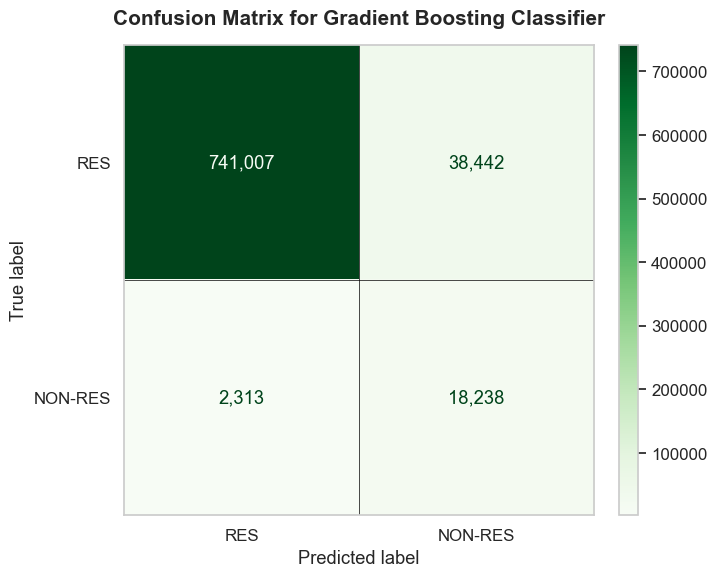

In [78]:
# Plot the confusion matrix
fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=gb_cm,
    display_labels=["RES", "NON-RES"]
)

disp.plot(
    cmap="Greens",
    colorbar=False,
    values_format=",d",
    ax=ax
)

from mpl_toolkits.axes_grid1 import make_axes_locatable

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%", pad=0.25)

fig.colorbar(disp.im_, cax=cax)

ax.axhline(0.5, color="black", linewidth=0.5)
ax.axvline(0.5, color="black", linewidth=0.5)

ax.set_title(
    "Confusion Matrix for Gradient Boosting Classifier",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.grid(False)
plt.tight_layout()
plt.show()

#### Key Findings

- High NON-RES recall (0.8875) is accompanied by low precision (0.3218), indicating a substantial number of false positives.
- ROC-AUC (0.9719) and Average Precision (0.7677) indicate strong discriminatory performance.
- Low standard deviations indicate consistent performance across validation folds.
- Classification threshold optimization may improve the precision–recall balance.

### 3.3 XGBoost Classifier

XGBoost is an optimized gradient boosting algorithm that incorporates regularization to improve generalization. Class imbalance is addressed using the `scale_pos_weight` parameter.

**Model Training and Cross-Validation**

In [79]:
from xgboost import XGBClassifier

# Define XGBoost pipeline
xgb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        subsample=0.8,
        tree_method="hist",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Initialize cross-validation results
xgb_results = []

# Initialize out-of-fold predictions
xgb_y_pred = np.zeros(len(X_train), dtype=int)
xgb_y_prob = np.zeros(len(X_train), dtype=float)

# Perform stratified cross-validation
for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train_encoded), start=1
):
    print(f"Training fold {fold}/{cv.n_splits}...", flush=True)

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train_encoded.iloc[train_idx]
    y_fold_val = y_train_encoded.iloc[val_idx]

    # Calculate class imbalance ratio
    scale_pos_weight = (
        (y_fold_train == 0).sum() /
        (y_fold_train == 1).sum()
    )

    # Train the model
    xgb_fold_model = clone(xgb_pipeline)

    xgb_fold_model.set_params(
        classifier__scale_pos_weight=scale_pos_weight
    )

    xgb_fold_model.fit(X_fold_train, y_fold_train)

    # Generate validation predictions
    y_pred_fold = xgb_fold_model.predict(X_fold_val)
    y_prob_fold = xgb_fold_model.predict_proba(X_fold_val)[:, 1]

    # Store out-of-fold predictions
    xgb_y_pred[val_idx] = y_pred_fold
    xgb_y_prob[val_idx] = y_prob_fold

    # Store fold evaluation metrics
    xgb_results.append({
        "Accuracy": accuracy_score(y_fold_val, y_pred_fold),
        "Balanced Accuracy": balanced_accuracy_score(y_fold_val, y_pred_fold),
        "Precision": precision_score(y_fold_val, y_pred_fold, zero_division=0),
        "Recall": recall_score(y_fold_val, y_pred_fold, zero_division=0),
        "F1-score": f1_score(y_fold_val, y_pred_fold, zero_division=0),
        "ROC-AUC": roc_auc_score(y_fold_val, y_prob_fold),
        "Average Precision": average_precision_score(y_fold_val, y_prob_fold),
        "Log Loss": log_loss(y_fold_val, y_prob_fold),
        "Brier Score": brier_score_loss(y_fold_val, y_prob_fold)
    })

    print(f"Fold {fold}/{cv.n_splits} completed", flush=True)

Training fold 1/3...
Fold 1/3 completed
Training fold 2/3...
Fold 2/3 completed
Training fold 3/3...
Fold 3/3 completed


**Evaluation Metrics and Classification Report**

In [80]:
# Summarize cross-validation performance
xgb_cv_results = pd.DataFrame(xgb_results)

xgb_summary = pd.DataFrame({
    "Mean": xgb_cv_results.mean(),
    "Std": xgb_cv_results.std()
})

# Store mean evaluation metrics
xgb_accuracy = xgb_summary.loc["Accuracy", "Mean"]
xgb_balanced_accuracy = xgb_summary.loc["Balanced Accuracy", "Mean"]
xgb_precision = xgb_summary.loc["Precision", "Mean"]
xgb_recall = xgb_summary.loc["Recall", "Mean"]
xgb_f1 = xgb_summary.loc["F1-score", "Mean"]
xgb_roc_auc = xgb_summary.loc["ROC-AUC", "Mean"]
xgb_average_precision = xgb_summary.loc["Average Precision", "Mean"]
xgb_log_loss = xgb_summary.loc["Log Loss", "Mean"]
xgb_brier_score = xgb_summary.loc["Brier Score", "Mean"]

In [81]:
# Generate classification report and confusion matrix
xgb_report = classification_report(
    y_train_encoded,
    xgb_y_pred,
    target_names=target_names,
    zero_division=0
)

xgb_cm = confusion_matrix(y_train_encoded, xgb_y_pred)

# Display evaluation results
print("--- XGBoost Classifier (Mean ± Std) ---\n")

for metric, row in xgb_summary.iterrows():
    print(f"{metric}: {row['Mean']:.4f} ± {row['Std']:.4f}")

print("\nClassification Report:\n")
print(xgb_report)

--- XGBoost Classifier (Mean ± Std) ---

Accuracy: 0.9522 ± 0.0005
Balanced Accuracy: 0.9185 ± 0.0005
Precision: 0.3363 ± 0.0025
Recall: 0.8829 ± 0.0013
F1-score: 0.4871 ± 0.0025
ROC-AUC: 0.9729 ± 0.0002
Average Precision: 0.7909 ± 0.0016
Log Loss: 0.1853 ± 0.0007
Brier Score: 0.0462 ± 0.0003

Classification Report:

                           precision    recall  f1-score   support

        Residential (RES)       1.00      0.95      0.97    779449
Non-Residential (NON-RES)       0.34      0.88      0.49     20551

                 accuracy                           0.95    800000
                macro avg       0.67      0.92      0.73    800000
             weighted avg       0.98      0.95      0.96    800000



**Confusion Matrix**

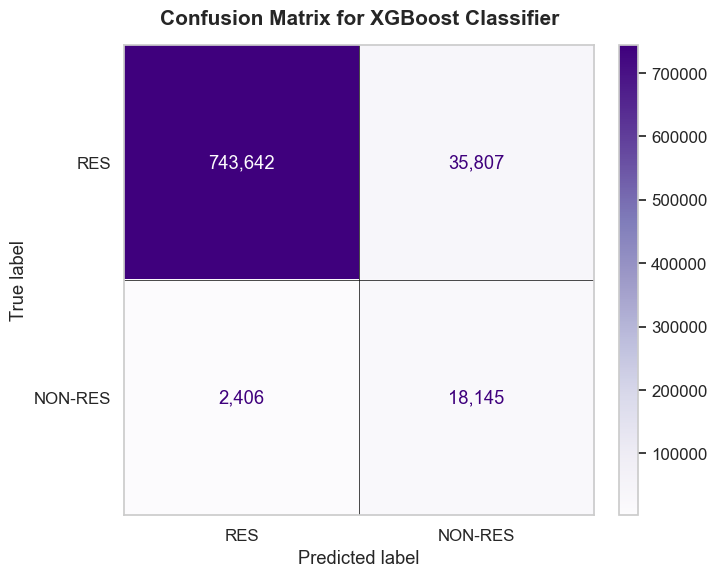

In [82]:
# Plot the confusion matrix
fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=xgb_cm,
    display_labels=["RES", "NON-RES"]
)

disp.plot(
    cmap="Purples",
    colorbar=False,
    values_format=",d",
    ax=ax
)

# Align the colorbar with the confusion matrix
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%", pad=0.25)

fig.colorbar(disp.im_, cax=cax)

ax.axhline(0.5, color="black", linewidth=0.5)
ax.axvline(0.5, color="black", linewidth=0.5)

ax.set_title(
    "Confusion Matrix for XGBoost Classifier",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.grid(False)
plt.tight_layout()
plt.show()

#### Key Findings

- High NON-RES recall (0.8829) is accompanied by low precision (0.3363), although precision and F1-score improve compared to Gradient Boosting.
- ROC-AUC (0.9729) and Average Precision (0.7909) indicate strong discriminatory performance.
- Low standard deviations indicate consistent performance across validation folds.

### 3.4 CatBoost Classifier

CatBoost is a gradient boosting algorithm that incorporates techniques to reduce overfitting. For consistency across models, the same preprocessing pipeline is used. Class imbalance is addressed through automatic class weighting.

**Model Training and Cross-Validation**

In [83]:
from catboost import CatBoostClassifier

# Define CatBoost pipeline
cb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", CatBoostClassifier(
        iterations=100,
        learning_rate=0.1,
        depth=3,
        loss_function="Logloss",
        auto_class_weights="Balanced",
        random_seed=42,
        thread_count=-1,
        verbose=False,
        allow_writing_files=False
    ))
])

# Initialize cross-validation results
cb_results = []

# Initialize out-of-fold predictions
cb_y_pred = np.zeros(len(X_train), dtype=int)
cb_y_prob = np.zeros(len(X_train), dtype=float)

# Perform stratified cross-validation
for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train_encoded), start=1
):
    print(f"Training fold {fold}/{cv.n_splits}...", flush=True)

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train_encoded.iloc[train_idx]
    y_fold_val = y_train_encoded.iloc[val_idx]

    # Train the model
    cb_fold_model = clone(cb_pipeline)
    cb_fold_model.fit(X_fold_train, y_fold_train)

    # Generate validation predictions
    y_pred_fold = cb_fold_model.predict(X_fold_val).ravel()
    y_prob_fold = cb_fold_model.predict_proba(X_fold_val)[:, 1]

    # Store out-of-fold predictions
    cb_y_pred[val_idx] = y_pred_fold
    cb_y_prob[val_idx] = y_prob_fold

    # Store fold evaluation metrics
    cb_results.append({
        "Accuracy": accuracy_score(y_fold_val, y_pred_fold),
        "Balanced Accuracy": balanced_accuracy_score(y_fold_val, y_pred_fold),
        "Precision": precision_score(y_fold_val, y_pred_fold, zero_division=0),
        "Recall": recall_score(y_fold_val, y_pred_fold, zero_division=0),
        "F1-score": f1_score(y_fold_val, y_pred_fold, zero_division=0),
        "ROC-AUC": roc_auc_score(y_fold_val, y_prob_fold),
        "Average Precision": average_precision_score(y_fold_val, y_prob_fold),
        "Log Loss": log_loss(y_fold_val, y_prob_fold),
        "Brier Score": brier_score_loss(y_fold_val, y_prob_fold)
    })

    print(f"Fold {fold}/{cv.n_splits} completed", flush=True)

Training fold 1/3...
Fold 1/3 completed
Training fold 2/3...
Fold 2/3 completed
Training fold 3/3...
Fold 3/3 completed


**Evaluation Metrics and Classification Report**

In [84]:
# Summarize cross-validation performance
cb_cv_results = pd.DataFrame(cb_results)

cb_summary = pd.DataFrame({
    "Mean": cb_cv_results.mean(),
    "Std": cb_cv_results.std()
})

# Store mean evaluation metrics
cb_accuracy = cb_summary.loc["Accuracy", "Mean"]
cb_balanced_accuracy = cb_summary.loc["Balanced Accuracy", "Mean"]
cb_precision = cb_summary.loc["Precision", "Mean"]
cb_recall = cb_summary.loc["Recall", "Mean"]
cb_f1 = cb_summary.loc["F1-score", "Mean"]
cb_roc_auc = cb_summary.loc["ROC-AUC", "Mean"]
cb_average_precision = cb_summary.loc["Average Precision", "Mean"]
cb_log_loss = cb_summary.loc["Log Loss", "Mean"]
cb_brier_score = cb_summary.loc["Brier Score", "Mean"]

In [85]:
# Generate classification report and confusion matrix
cb_report = classification_report(
    y_train_encoded,
    cb_y_pred,
    target_names=target_names,
    zero_division=0
)

cb_cm = confusion_matrix(y_train_encoded, cb_y_pred)

# Display evaluation results
print("--- CatBoost Classifier (Mean ± Std) ---\n")

for metric, row in cb_summary.iterrows():
    print(f"{metric}: {row['Mean']:.4f} ± {row['Std']:.4f}")

print("\nClassification Report:\n")
print(cb_report)

--- CatBoost Classifier (Mean ± Std) ---

Accuracy: 0.9506 ± 0.0028
Balanced Accuracy: 0.9081 ± 0.0076
Precision: 0.3260 ± 0.0111
Recall: 0.8633 ± 0.0182
F1-score: 0.4731 ± 0.0095
ROC-AUC: 0.9671 ± 0.0039
Average Precision: 0.7464 ± 0.0098
Log Loss: 0.2011 ± 0.0073
Brier Score: 0.0502 ± 0.0023

Classification Report:

                           precision    recall  f1-score   support

        Residential (RES)       1.00      0.95      0.97    779449
Non-Residential (NON-RES)       0.33      0.86      0.47     20551

                 accuracy                           0.95    800000
                macro avg       0.66      0.91      0.72    800000
             weighted avg       0.98      0.95      0.96    800000



**Confusion Matrix**

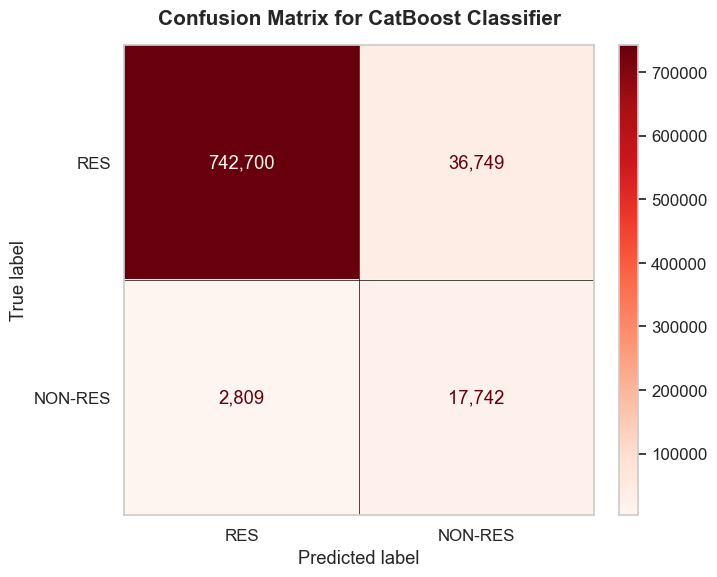

In [86]:
# Plot the confusion matrix
fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cb_cm,
    display_labels=["RES", "NON-RES"]
)

disp.plot(
    cmap="Reds",
    colorbar=False,
    values_format=",d",
    ax=ax
)

# Align the colorbar with the confusion matrix
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%", pad=0.25)

fig.colorbar(disp.im_, cax=cax)

ax.axhline(0.5, color="black", linewidth=0.5)
ax.axvline(0.5, color="black", linewidth=0.5)

ax.set_title(
    "Confusion Matrix for CatBoost Classifier",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.grid(False)
plt.tight_layout()
plt.show()

#### Key Findings

- High NON-RES recall (0.8633) is accompanied by low precision (0.3260).
- ROC-AUC (0.9671) and Average Precision (0.7464) are lower than those of the other evaluated models.
- Higher standard deviations indicate greater performance variability across validation folds.

### 3.5 Model Comparison

The models are compared using cross-validation results to assess classification performance, minority-class detection, prediction reliability, and consistency across validation folds.

**Performance Summary**

In [87]:
# Combine mean cross-validation metrics
model_results = pd.DataFrame({
    "Gradient Boosting": gb_summary["Mean"],
    "XGBoost": xgb_summary["Mean"],
    "CatBoost": cb_summary["Mean"]
})

# Combine standard deviations
model_std = pd.DataFrame({
    "Gradient Boosting": gb_summary["Std"],
    "XGBoost": xgb_summary["Std"],
    "CatBoost": cb_summary["Std"]
})

# Define consistent model colors
model_colors = {
    "Gradient Boosting": "#228B22",
    "XGBoost": "#800080",
    "CatBoost": "#D62728"
}

# Identify metrics where lower values are better
loss_metrics = ["Log Loss", "Brier Score"]

# Highlight the best result for each metric
def highlight_best(row):
    best = row.min() if row.name in loss_metrics else row.max()

    return [
        "font-weight: bold; background-color: #E2F0D9"
        if value == best else ""
        for value in row
    ]

# Display model performance comparison
display(
    model_results.style
    .format("{:.4f}")
    .apply(highlight_best, axis=1)
)

,Gradient Boosting,XGBoost,CatBoost
Accuracy,0.9491,0.9522,0.9506
Balanced Accuracy,0.9191,0.9185,0.9081
Precision,0.3218,0.3363,0.3260
Recall,0.8875,0.8829,0.8633
F1-score,0.4723,0.4871,0.4731
ROC-AUC,0.9719,0.9729,0.9671
Average Precision,0.7677,0.7909,0.7464
Log Loss,0.1937,0.1853,0.2011
Brier Score,0.0487,0.0462,0.0502


**Model Performance Heatmap**

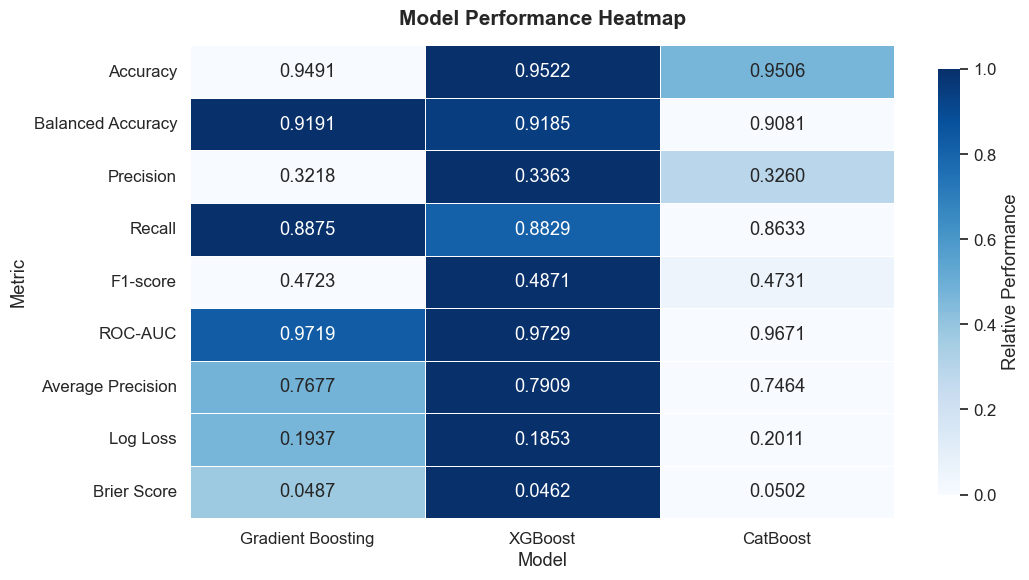

In [88]:
# Normalize performance metrics row-wise
heatmap_data = model_results.copy()

for metric in heatmap_data.index:
    values = model_results.loc[metric]
    value_range = values.max() - values.min()

    if value_range == 0:
        heatmap_data.loc[metric] = 0.5
    elif metric in loss_metrics:
        heatmap_data.loc[metric] = (
            values.max() - values
        ) / value_range
    else:
        heatmap_data.loc[metric] = (
            values - values.min()
        ) / value_range

# Plot model performance heatmap
plt.figure(figsize=(11, 6))

sns.heatmap(
    heatmap_data,
    annot=model_results,
    fmt=".4f",
    cmap="Blues",
    linewidths=0.5,
    linecolor="white",
    vmin=0,
    vmax=1,
    cbar_kws={
        "label": "Relative Performance",
        "shrink": 0.9
    }
)

plt.title(
    "Model Performance Heatmap",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("Model")
plt.ylabel("Metric")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

*Color intensity represents relative performance within each metric. Darker shades indicate better results, while annotations display the original metric values.*

**Model Performance Bar Chart**

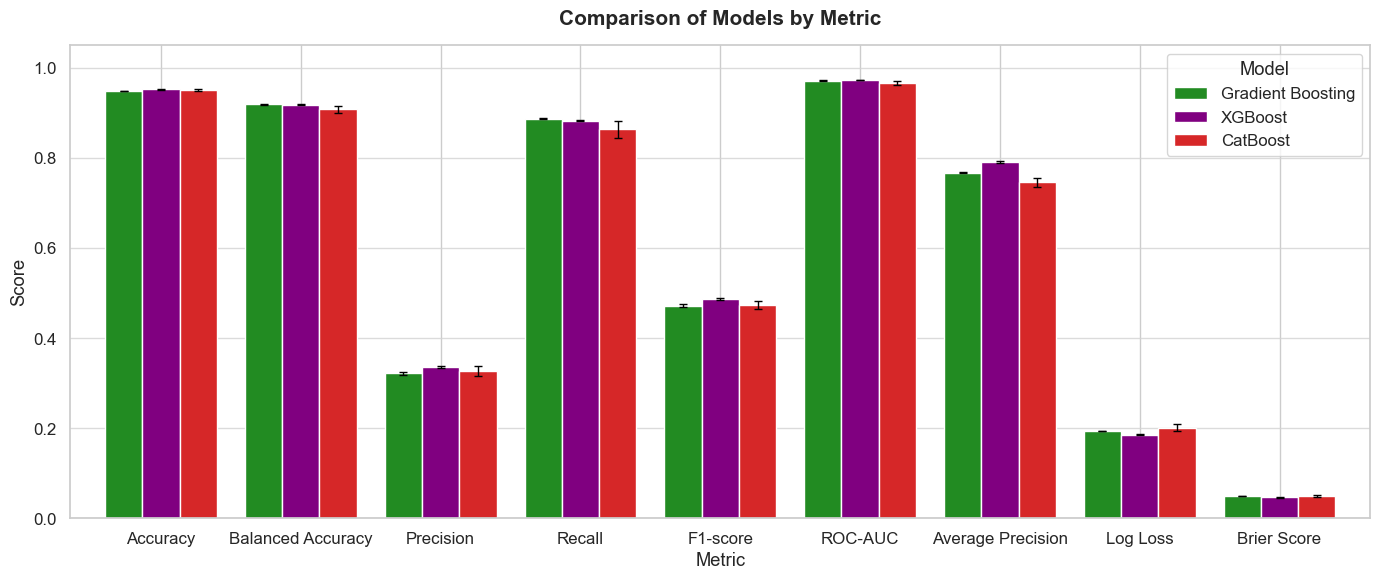

In [89]:
# Plot model performance with standard deviations
ax = model_results.plot(
    kind="bar",
    figsize=(14, 6),
    color=[model_colors[model] for model in model_results.columns],
    yerr=model_std,
    capsize=3,
    width=0.8,
    edgecolor="white",
    error_kw={"elinewidth": 1, "ecolor": "black"}
)

ax.set_title(
    "Comparison of Models by Metric",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)

plt.xticks(rotation=0)

ax.grid(
    axis="y",
    linestyle="-",
    color="lightgray",
    linewidth=1,
    alpha=0.8
)

ax.set_axisbelow(True)
ax.legend(title="Model", loc="upper right")

plt.tight_layout()
plt.show()

*Error bars represent ±1 standard deviation across the three validation folds. Higher values indicate better performance, except for Log Loss and Brier Score.*

**Key Findings**

- XGBoost achieved the highest Average Precision (0.7909), F1-score (0.4871), and ROC-AUC (0.9729).
- Gradient Boosting achieved the highest Recall (0.8875) and Balanced Accuracy (0.9191).
- CatBoost exhibited greater performance variability across validation folds.
- All three models achieved high recall but relatively low precision for the NON-RES class.
- XGBoost demonstrated the best overall performance and is the preferred candidate for further evaluation.

### 3.6 Model Interpretation

Permutation Importance is used to identify and compare the most influential features across the three classification models. Feature importance is measured by the decrease in Average Precision after randomly shuffling each feature.

In [90]:
# Identify available trained models and pipelines
from sklearn.base import BaseEstimator
from sklearn.utils.validation import check_is_fitted

for name, obj in list(globals().items()):
    if isinstance(obj, BaseEstimator):
        try:
            check_is_fitted(obj)
            print(f"{name}: {type(obj).__name__}")
        except Exception:
            pass

gb_fold_model: Pipeline
xgb_fold_model: Pipeline
cb_fold_model: Pipeline


In [91]:
# Identify available validation datasets
for name in list(globals()):
    if "val" in name.lower():
        obj = globals()[name]
        if hasattr(obj, "shape"):
            print(f"{name}: {obj.shape}")

values: (3,)
plot_values: (745667,)
valid_ids: (221982, 78)
dominant_value: ()
dtype_validation: (12, 3)
invalid_values: (0,)
validity_summary: (27, 5)
equipment_validation: (8, 3)
equipment_prevalence: (8, 2)
x_values: (200,)
y_values: (200,)
valid: (1000000,)
invalid_price_mask: (1000000,)
val_idx: (266666,)
X_fold_val: (266666, 37)
y_fold_val: (266666,)


In [92]:
from sklearn.inspection import permutation_importance

# Create a stratified validation subset
X_importance, _, y_importance, _ = train_test_split(
    X_fold_val,
    y_fold_val,
    train_size=50000,
    stratify=y_fold_val,
    random_state=42
)

# Define trained models
trained_models = {
    "Gradient Boosting": gb_fold_model,
    "XGBoost": xgb_fold_model,
    "CatBoost": cb_fold_model
}

# Calculate permutation importance
feature_importances = {}

for model_name, model in trained_models.items():
    print(f"Calculating feature importance: {model_name}...",
          flush=True)

    result = permutation_importance(
        model,
        X_importance,
        y_importance,
        scoring="average_precision",
        n_repeats=3,
        random_state=42,
        n_jobs=1
    )

    feature_importances[model_name] = pd.Series(
        result.importances_mean,
        index=X_importance.columns
    )

    print(f"{model_name}: completed", flush=True)

# Combine feature importance results
importance_df = pd.DataFrame(feature_importances)

display(importance_df.round(4))

Calculating feature importance: Gradient Boosting...
Gradient Boosting: completed
Calculating feature importance: XGBoost...
XGBoost: completed
Calculating feature importance: CatBoost...
CatBoost: completed


,Gradient Boosting,XGBoost,CatBoost
Variable,,,
system_size_DC,0.3169,0.2356,0.2473
total_installed_price,0.0018,0.0008,0.0038
expansion_system,-0.0001,0.0006,-0.0001
multiple_phase_system,0.0095,0.0083,0.0103
new_construction,0.2872,0.3016,0.0885
tracking,0.0001,0.0004,0.0000
ground_mounted,0.0001,-0.0001,-0.0004
zip_code,0.0020,0.0013,0.0034
city,0.0016,0.0007,0.0000


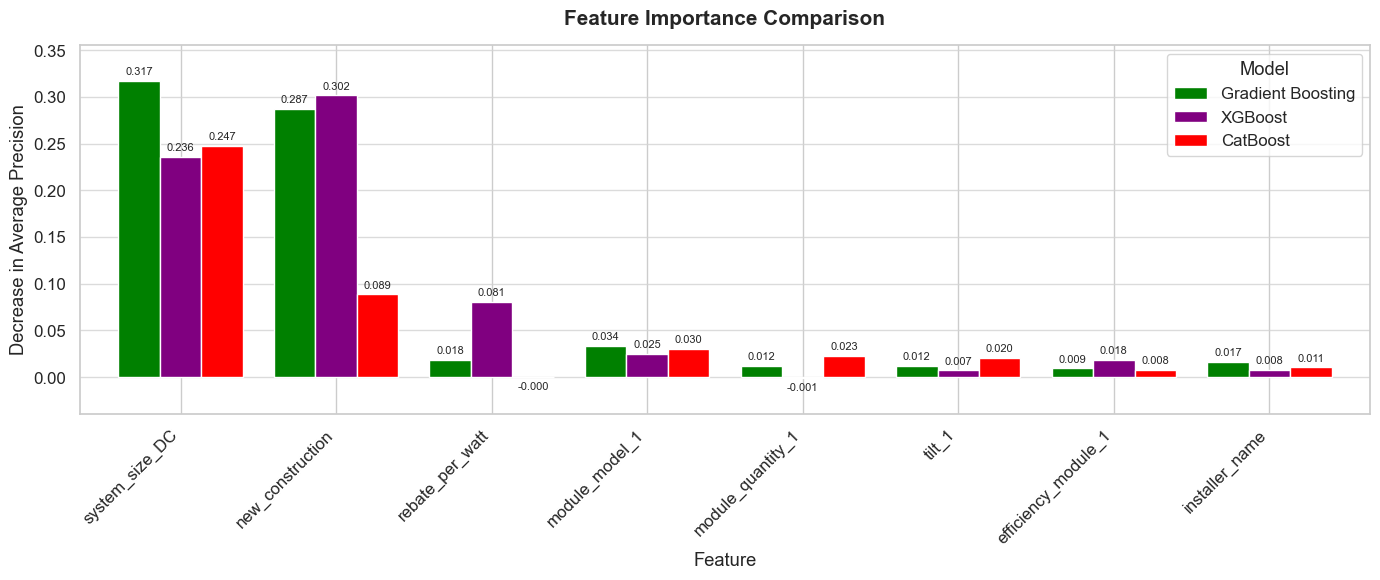

In [93]:
# Select the top 5 features from each model
top_features = set()

for model in importance_df.columns:
    top_features.update(
        importance_df[model].nlargest(5).index
    )

# Sort features by maximum importance
importance_plot = importance_df.loc[sorted(top_features)]

importance_plot = importance_plot.loc[
    importance_plot.max(axis=1)
    .sort_values(ascending=False).index
]

# Plot feature importance comparison
ax = importance_plot.plot(
    kind="bar",
    figsize=(14, 6),
    color=["green", "purple", "red"],
    width=0.8
)

ax.set_title(
    "Feature Importance Comparison",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Feature")
ax.set_ylabel("Decrease in Average Precision")

plt.xticks(rotation=45, ha="right")

ax.grid(
    axis="y",
    linestyle="-",
    color="lightgray",
    alpha=0.8
)

ax.set_axisbelow(True)
ax.legend(title="Model")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=3)

ax.margins(y=0.12)

plt.tight_layout()
plt.show()

*The chart includes the five most important features from each model. Importance is measured as the mean decrease in Average Precision across three permutation repeats on a stratified validation subset of 50,000 observations from the final CV fold.*

**Key Findings**

- System size and new construction status are the two most influential features across all three models.
- XGBoost relies more heavily on rebate per watt than the other models.
- The high importance of new construction may reflect segment-specific missingness rather than construction status itself, indicating a potential data leakage risk.

### 3.7 Modeling Summary

**Model Performance**

- All three models demonstrated strong class discrimination, with ROC-AUC scores above 0.96.
- Class weighting enabled effective detection of the minority class, with NON-RES recall ranging from 86.33% to 88.75%.
- Relatively low precision indicates that false-positive predictions remain a challenge.
- Stratified three-fold cross-validation showed relatively consistent performance across validation folds.

**Best Model Selection**

XGBoost demonstrated the strongest overall performance, achieving the highest scores in seven of the nine evaluation metrics, including:

- Average Precision: 0.7909
- F1-score: 0.4871
- ROC-AUC: 0.9729

Although Gradient Boosting achieved slightly higher Recall and Balanced Accuracy, XGBoost provided the best balance between minority-class detection and overall predictive performance.

Therefore, XGBoost is selected for further evaluation and optimization.

**Key Predictive Features**

- System size and new construction status were the most influential features across all three models.
- The importance of system size supports the findings from exploratory data analysis.
- Rebate per watt was particularly influential in XGBoost.
- Module model demonstrated consistent predictive relevance across all three models.

**Limitations and Risks**

- Strong class imbalance remains a classification challenge.
- Low minority-class precision indicates a substantial number of false positives.
- Segment-specific missingness in the `new_construction` feature represents a potential data leakage risk that has not been independently investigated.
- The default classification threshold may not provide the optimal balance between precision and recall.

**General Conclusion**

The modeling stage successfully identified XGBoost as the most promising classifier for distinguishing residential and non-residential solar installations, based on cross-validation performance.